# 03 — Features, target and the modelling table

**Canvas project group:** 37 · **Members:** Nat Toms, Owen Cruz-Abrams, Martha le Huray

**Purpose.** This notebook turns the cleaned SNOTEL table (notebook 02) and the Open-Meteo reanalysis downloads into the
table we will model in Milestone 3. **One row = (resort, issue date *t*).** The columns are what a forecaster could know at
the end of day *t*, plus the target: **measured SNOTEL snow depth on day *t* + 30**. Along the way it completes the
cleaning checklist for the **weather inputs**: lineage, missingness, physical consistency, outliers, consistency over time,
agreement with station observations, and feature scale. It then defines and justifies the **train / validation / test split
by winter** and scores the **baselines** the staff asked for: climatology from training winters only, plus persistence.

| § | What | MS2 item |
|---|---|---|
| 1 | Inputs and lineage: every raw file re-hashed, every request parameter audited | getting the data, size |
| 2 | Open-Meteo weather inputs: grid cells, completeness, physical checks, outliers, consistency over time, agreement with SNOTEL | cleaning: missing data, unusual values |
| 3 | Target: the Aspen composite, measured coverage, seasonal curves | understanding the data, response |
| 4 | Features: catalogue, leakage audit on real data, look-ahead in upstream cleaning steps | leakage |
| 5 | Labels, row accounting, the modelling table | what a row is, shape |
| 6 | Train / validation / test split by winter, and why a random split would leak | staff conditions 3–4 |
| 7 | Baselines: climatology (training winters only), persistence, persistence plus the climatological change | staff condition 2 |
| 8 | EDA of the modelling table: target distribution, feature–target relationships, collinearity, scale | feature scale |
| 9 | Robustness inputs from NRCS's original readings (D-024) | leakage |
| 10 | Outputs, data dictionary, sizes | — |
| 11 | Findings and proposed decisions (D-029 to D-037) | revised question |

**Offline.** `SNOWPREDICT_OFFLINE=1`: this notebook can only read logged raw data; any download attempt raises an error.
The reusable logic is in `src/modeltable.py`. Its leakage guarantees are unit-tested in `tests/test_modeltable.py`
(truncation and future-perturbation tests), and §4.2 re-runs the same checks on the real data.

In [1]:
import os, sys, re, hashlib, json
from pathlib import Path
from urllib.parse import urlsplit, parse_qs
os.environ["SNOWPREDICT_OFFLINE"] = "1"          # never download from this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import lineage, parse, sites, features, modeltable as mt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11})
OUT = ROOT / "data" / "processed"
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)       # PNGs for the slides
RES = sites.RESORTS
STATIONS = [t for c in RES.values() for t in c["stations"]]
RESORT_OF = {t: r for r, c in RES.items() for t in c["stations"]}
COL = {"Aspen": "#1f77b4", "Brighton": "#ff7f0e", "Heavenly": "#2ca02c"}
SPLIT_COL = {"train": "#8c8c8c", "val": "#e6a100", "test": "#d62728"}
def savefig(fig, name):
    fig.savefig(FIG / f"03_{name}.png", bbox_inches="tight", dpi=150)
print("resorts:", {r: c["stations"] for r, c in RES.items()})
print("horizon:", mt.HORIZON, "days | windows:", mt.WINDOWS, "| splits:", mt.SPLIT_BOUNDS)

resorts: {'Aspen': ['556:CO:SNTL', '369:CO:SNTL'], 'Brighton': ['366:UT:SNTL'], 'Heavenly': ['518:CA:SNTL']}
horizon: 30 days | windows: (7, 30) | splits: {'train': (None, 2016), 'val': (2017, 2020), 'test': (2021, 2026)}


## 1. Inputs and lineage
**Inputs**
- `data/processed/snotel_clean.parquet` (notebook 02). We record its SHA-256 so the exact version used is known.
- The 48 Open-Meteo feature chunks: 4 stations × 2 models × 6 five-year chunks, fetched by `scripts/prefetch_features.py`
  with the request definitions in `src/features.py`.
- The SNOTEL station metadata file, which supplies station coordinates (never typed by hand).

For each feature chunk we take the **latest** manifest row for its URL and re-compute the file's SHA-256. We also parse the
logged URL back into its parameters, to confirm three things: the model was pinned (never `best_match`, D-002), an explicit
`elevation=` was sent, and `timezone=auto` was used.

In [2]:
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
clean_path = OUT / "snotel_clean.parquet"
print(f"snotel_clean.parquet  {clean_path.stat().st_size/1e6:.2f} MB  sha256 {sha(clean_path)}")

man = lineage.manifest()
fm = man[man.name.str.startswith("feat_")].copy()
print(f"manifest rows for feature requests: {len(fm)} "
      f"(HTTP status counts: {fm.http_status.value_counts().to_dict()}; 429 rows are logged, never cached — D-028)")
latest = fm.sort_values("fetched_utc").groupby("url").tail(1)
assert (latest.http_status == 200).all(), "every feature URL must end in a successful download"

def qp(u):
    return {k: v[0] for k, v in parse_qs(urlsplit(u).query).items()}
P = pd.DataFrame([qp(u) for u in latest.url])
P["name"], P["file"], P["sha256"], P["bytes"] = latest.name.values, latest.file.values, latest.sha256.values, latest.bytes.values
m = P.name.str.extract(r"^feat_(era5_land|era5)_(\d+_[A-Z]{2}_SNTL)_(\d{4})$")
P["model_tag"], P["station"] = m[0], m[1].str.replace("_", ":")
P["sha_ok"] = [sha(ROOT / f) == s for f, s in zip(P.file, P.sha256)]
checks = {
    "files present & SHA-256 match": P.sha_ok.all(),
    "models pinned (era5 / era5_land only)": P.models.isin(["era5", "era5_land"]).all() and P.models.eq(P.model_tag).all(),
    "no best_match anywhere": not P.models.str.contains("best_match").any(),
    "explicit elevation on every request": P.elevation.notna().all(),
    "timezone=auto on every request": P.timezone.eq("auto").all(),
    "4 stations x 2 models x 6 chunks": len(P) == 48 and P.groupby(["station", "models"]).size().eq(6).all(),
}
display(pd.Series(checks, name="pass").to_frame())
assert all(checks.values())
print(f"total feature data: {P.bytes.astype(int).sum()/1e6:.2f} MB in {len(P)} files")
P.groupby(["station", "models"]).agg(elevation_m=("elevation", "first"), chunks=("name", "size"),
                                     first=("start_date", "min"), last=("end_date", "max"),
                                     MB=("bytes", lambda b: b.astype(int).sum() / 1e6)).round(2)

snotel_clean.parquet  4.51 MB  sha256 a81666942ec0ca44217e763620f3f100cddd881c084231924dd6c102e122136c
manifest rows for feature requests: 49 (HTTP status counts: {200: 48, 429: 1}; 429 rows are logged, never cached — D-028)


,pass
files present & SHA-256 match,True
models pinned (era5 / era5_land only),True
no best_match anywhere,True
explicit elevation on every request,True
timezone=auto on every request,True
4 stations x 2 models x 6 chunks,True


total feature data: 4.11 MB in 48 files


elevation_m  chunks       first        last    MB
station     models                                                     
366:UT:SNTL era5             2679       6  1997-07-01  2026-06-30  0.68
            era5_land        2679       6  1997-07-01  2026-06-30  0.35
369:CO:SNTL era5             3222       6  1997-07-01  2026-06-30  0.68
            era5_land        3222       6  1997-07-01  2026-06-30  0.35
518:CA:SNTL era5             2603       6  1997-07-01  2026-06-30  0.68
            era5_land        2603       6  1997-07-01  2026-06-30  0.34
556:CO:SNTL era5             2929       6  1997-07-01  2026-06-30  0.68
            era5_land        2929       6  1997-07-01  2026-06-30  0.35

In [3]:
meta_raw = lineage.snotel("stations", {"stationTriplets": ",".join(sites.CANDIDATE_STATIONS), "returnStationElements": "true"},
                          name="stations_candidates_elements")
meta = pd.DataFrame([{k: s[k] for k in ["stationTriplet", "name", "elevation", "latitude", "longitude"]}
                     for s in meta_raw]).set_index("stationTriplet").loc[STATIONS]
meta["elev_m"] = (meta.elevation * 0.3048).round()
meta["resort"] = [RESORT_OF[t] for t in meta.index]
F = {t: features.fetch_station(t, meta.loc[t, "latitude"], meta.loc[t, "longitude"], meta.loc[t, "elevation"] * 0.3048)
     for t in STATIONS}                                           # offline: served from data/raw only
clean = pd.read_parquet(clean_path)
print("clean SNOTEL table:", clean.shape)
meta

clean SNOTEL table: (285778, 49)


,name,elevation,latitude,longitude,elev_m,resort
stationTriplet,,,,,,
556:CO:SNTL,Kiln,9610.0,39.31720,-106.61501,2929.0,Aspen
369:CO:SNTL,Brumley,10570.0,39.08758,-106.54231,3222.0,Aspen
366:UT:SNTL,Brighton,8790.0,40.59936,-111.58167,2679.0,Brighton
518:CA:SNTL,Heavenly Valley,8540.0,38.92431,-119.91641,2603.0,Heavenly


## 2. Open-Meteo weather inputs: quality checks
Reanalysis output is gridded and gap-free by construction, but that does not mean it can be trusted unchecked. We check:
(2.1) **which grid cell** each request actually got; (2.2) completeness and the seams between 5-year chunks;
(2.3) physical consistency; (2.4) outliers and known extreme events; (2.5) **consistency over time**, meaning no artificial
jumps (the `best_match` trap, D-002); (2.6) agreement with the station's own measurements; and (2.7) whether the two Aspen
stations really see different weather.

### 2.1 Which grid cell did we get?
Each response states the grid-cell centre it used. Open-Meteo's default `cell_selection=land` does **not** simply take the
nearest cell. It searches nearby land cells for one whose terrain elevation is close to the requested `elevation=`, using a
90 m elevation model. We did not set `cell_selection`, so the default applied. The table records what we actually got.

In [4]:
def hav(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

rows = []
for (t, model), g in P.groupby(["station", "models"]):
    js = [json.loads((ROOT / f).read_bytes()) for f in g.file]
    lat = {j["latitude"] for j in js}; lon = {j["longitude"] for j in js}
    j = js[0]
    rows.append({"resort": RESORT_OF[t], "station": meta.loc[t, "name"], "model": model,
                 "station lat/lon": f"{meta.loc[t,'latitude']:.3f}, {meta.loc[t,'longitude']:.3f}",
                 "grid lat/lon": f"{j['latitude']:.2f}, {j['longitude']:.2f}",
                 "same cell in all chunks": len(lat) == 1 and len(lon) == 1,
                 "km from station": round(hav(meta.loc[t, "latitude"], meta.loc[t, "longitude"], j["latitude"], j["longitude"]), 1),
                 "elevation sent (m)": float(g.elevation.iloc[0]), "elevation returned (m)": j["elevation"],
                 "timezone": j["timezone"], "UTC offset (h)": j["utc_offset_seconds"] / 3600})
GRID = pd.DataFrame(rows)
GRID

,resort,station,model,station lat/lon,grid lat/lon,same cell in all chunks,km from station,elevation sent (m),elevation returned (m),timezone,UTC offset (h)
0,Brighton,Brighton,era5,"40.599, -111.582","40.50, -111.50",True,13.0,2679.0,2679.0,America/Denver,-7.0
1,Brighton,Brighton,era5_land,"40.599, -111.582","40.60, -111.60",True,1.5,2679.0,2679.0,America/Denver,-7.0
2,Aspen,Brumley,era5,"39.088, -106.542","39.00, -106.50",True,10.4,3222.0,3222.0,America/Denver,-7.0
3,Aspen,Brumley,era5_land,"39.088, -106.542","39.10, -106.50",True,3.9,3222.0,3222.0,America/Denver,-7.0
4,Heavenly,Heavenly Valley,era5,"38.924, -119.916","39.00, -120.00",True,11.1,2603.0,2603.0,America/Los_Angeles,-8.0
5,Heavenly,Heavenly Valley,era5_land,"38.924, -119.916","38.90, -119.90",True,3.1,2603.0,2603.0,America/Los_Angeles,-8.0
6,Aspen,Kiln,era5,"39.317, -106.615","39.25, -106.50",True,12.4,2929.0,2929.0,America/Denver,-7.0
7,Aspen,Kiln,era5_land,"39.317, -106.615","39.30, -106.70",True,7.6,2929.0,2929.0,America/Denver,-7.0


**Reading the table.**
- All 48 chunks of a station/model use the **same** cell, so there is no change of cell inside a series.
- The returned elevation is the one we sent, which is what drives the temperature lapse-rate correction (notebook 01 §1.4).
- ERA5's cells are 0.25° (~28 km × 21 km) and ERA5-Land's are 0.1°, so a cell centre 5–20 km from the station is normal.
- `timezone=auto` resolved to each station's local zone. It is reported as a fixed standard-time offset, so **daily values are
  local-standard-time calendar days** (verified in notebook 01b §3–3b).

### 2.2 Completeness, duplicates and chunk seams
We need a continuous daily calendar with no duplicated days where the 5-year chunks meet, and no NaN. As a seam test, we
compare day-to-day changes **across** a chunk boundary with ordinary day-to-day changes. A processing artefact at the
boundary would show up as an unusually large jump there.

In [5]:
seams = [pd.Timestamp(s) for s, _ in features.chunks()][1:]
rows = []
for t, df in F.items():
    full = pd.date_range(features.FEATURE_START, features.FEATURE_END, freq="D")
    dd = df.diff().abs()
    pct = {c: (dd[c] < dd.loc[seams, c].max()).mean() for c in ["era5__temperature_2m_mean", "era5_land__snow_depth_mean"]}
    rows.append({"station": meta.loc[t, "name"], "days": len(df), "expected": len(full),
                 "missing days": len(full.difference(df.index)), "duplicate days": int(df.index.duplicated().sum()),
                 "NaN cells": int(df.isna().sum().sum()),
                 "largest seam |Δ tmean|, percentile of all days": round(100 * pct["era5__temperature_2m_mean"], 1),
                 "largest seam |Δ land snow depth|, percentile": round(100 * pct["era5_land__snow_depth_mean"], 1)})
pd.DataFrame(rows)

,station,days,expected,missing days,duplicate days,NaN cells,"largest seam |Δ tmean|, percentile of all days","largest seam |Δ land snow depth|, percentile"
0,Kiln,10592,10592,0,0,0,58.3,0.0
1,Brumley,10592,10592,0,0,0,45.0,0.0
2,Brighton,10592,10592,0,0,0,78.9,0.0
3,Heavenly Valley,10592,10592,0,0,0,41.1,0.0


Result: complete calendars (10,592 days, 1997-07-01 to 2026-06-30), no duplicate days and **no NaN**, so the weather inputs
need **no imputation**. The largest temperature jump on a seam day sits at the 41st–79th percentile of all day-to-day jumps, which
is ordinary. The snow-depth column of the seam test is uninformative: every seam falls on Jul 1, when there is no snow, so the
jump there is 0 (shown as percentile 0).

### 2.3 Physical consistency
We check internal and physical constraints, in **source units** (what Open-Meteo returned). Day length comes from the
astronomical CBM model (Forsythe et al. 1995) at the station latitude. Sunshine duration cannot exceed it, apart from a small
tolerance for how Open-Meteo defines "sunshine" (direct radiation above 120 W/m²) and for refraction at the horizon.

In [6]:
def day_length_h(lat, dates):
    J = dates.day_of_year.to_numpy()
    theta = 0.2163108 + 2 * np.arctan(0.9671396 * np.tan(0.00860 * (J - 186)))
    phi = np.arcsin(0.39795 * np.cos(theta))
    p, L = 0.8333 * np.pi / 180, lat * np.pi / 180
    return 24 - 24 / np.pi * np.arccos((np.sin(p) + np.sin(L) * np.sin(phi)) / (np.cos(L) * np.cos(phi)))

eps = 0.051  # values are rounded to 0.1
rows = {}
for t, df in F.items():
    e = lambda c: df[f"era5__{c}"]; l = lambda c: df[f"era5_land__{c}"]
    dl = pd.Series(day_length_h(meta.loc[t, "latitude"], df.index), index=df.index)
    sf_ratio = (e("snowfall_sum") / e("precipitation_sum")).where(e("precipitation_sum") > 0.5)
    rows[meta.loc[t, "name"]] = {
        "ERA5 tmin ≤ tmean ≤ tmax": int((~((e("temperature_2m_min") <= e("temperature_2m_mean") + eps) & (e("temperature_2m_mean") <= e("temperature_2m_max") + eps))).sum()),
        "ERA5-Land tmin ≤ tmean ≤ tmax": int((~((l("temperature_2m_min") <= l("temperature_2m_mean") + eps) & (l("temperature_2m_mean") <= l("temperature_2m_max") + eps))).sum()),
        "precipitation < 0": int((e("precipitation_sum") < 0).sum()),
        "snowfall < 0": int((e("snowfall_sum") < 0).sum()),
        "snowfall > 0 with precipitation = 0": int(((e("snowfall_sum") > 0.05) & (e("precipitation_sum") == 0)).sum()),
        "snowfall (cm) / precip (mm) > 0.7 (+rounding)": int(((e("snowfall_sum") > 0.7 * e("precipitation_sum") + 0.1)).sum()),
        "RH outside [0, 100] %": int((~e("relative_humidity_2m_mean").between(0, 100)).sum()),
        "cloud outside [0, 100] %": int((~e("cloud_cover_mean").between(0, 100)).sum()),
        "wind < 0": int((e("wind_speed_10m_max") < 0).sum()),
        "MSL pressure outside [940, 1080] hPa": int((~e("pressure_msl_mean").between(940, 1080)).sum()),
        "sunshine > astronomical day length + 0.25 h": int((e("sunshine_duration") / 3600 > dl + 0.25).sum()),
        "ERA5-Land snow depth < 0": int((l("snow_depth_mean") < 0).sum()),
        "max snowfall/precip ratio (precip > 0.5 mm)": round(float(sf_ratio.max()), 3),
    }
PHYS = pd.DataFrame(rows)
PHYS

,Kiln,Brumley,Brighton,Heavenly Valley
ERA5 tmin ≤ tmean ≤ tmax,0.00,0.00,0.0,0.0
ERA5-Land tmin ≤ tmean ≤ tmax,0.00,0.00,0.0,0.0
precipitation < 0,0.00,0.00,0.0,0.0
snowfall < 0,0.00,0.00,0.0,0.0
snowfall > 0 with precipitation = 0,270.00,321.00,168.0,127.0
snowfall (cm) / precip (mm) > 0.7 (+rounding),1295.00,1371.00,918.0,520.0
"RH outside [0, 100] %",0.00,0.00,0.0,0.0
"cloud outside [0, 100] %",0.00,0.00,0.0,0.0
wind < 0,0.00,0.00,0.0,0.0
"MSL pressure outside [940, 1080] hPa",0.00,0.00,0.0,0.0


**Reading the table.** Each count is the number of station-days that **violate** the rule; the last row is a ratio.
- Temperature ordering, non-negativity, RH, cloud, pressure and sunshine-versus-day-length checks: **zero violations** at all four
  stations.
- **Snowfall vs precipitation is not internally consistent.** Open-Meteo documents snowfall as 0.7 cm per mm of water
  equivalent, so we expected snowfall (cm) ≤ 0.7 × precipitation (mm). It isn't:
  - 520–1,371 days per station exceed that bound, on light and heavy precipitation days alike (§2.3a).
  - The ratio reaches 1.9–2.45.
  - 127–321 days per station have snowfall but zero precipitation. Those are tiny amounts: median 0.14 cm, and the smallest
    non-zero value is 0.07 cm = 0.1 mm × 0.7.

  The two variables must therefore be **derived separately**: ERA5 has distinct total-precipitation and snowfall fields, each
  rounded separately. We do **not** remove anything, because neither field is "wrong" on its own. But we treat them as two
  related, imperfect signals, and we **do not derive rain as `precipitation − snowfall/0.7`**. That revises D-027's statement
  that `rain_sum` is approximately derivable; see D-030.

#### 2.3a Snowfall/precipitation inconsistency, by precipitation amount

In [7]:
rows = []
for t, df in F.items():
    p_, s_ = df["era5__precipitation_sum"], df["era5__snowfall_sum"]
    for lo, hi in [(0, 0.5), (0.5, 2), (2, 5), (5, 200)]:
        m_ = (p_ > lo) & (p_ <= hi)
        rows.append({"station": meta.loc[t, "name"], "precip (mm/day)": f"({lo}, {hi}]", "days": int(m_.sum()),
                     "snowfall > 0.7·precip + 0.1 (%)": round(100 * ((s_ > 0.7 * p_ + 0.1) & m_).sum() / m_.sum(), 1),
                     "median snowfall/precip": round(float((s_ / p_)[m_].median()), 3)})
pd.DataFrame(rows).pivot(index="precip (mm/day)", columns="station", values="snowfall > 0.7·precip + 0.1 (%)")

station,Brighton,Brumley,Heavenly Valley,Kiln
precip (mm/day),,,,
"(0, 0.5]",13.1,17.3,11.0,16.9
"(0.5, 2]",20.1,20.3,15.5,18.9
"(2, 5]",22.8,23.7,16.7,23.1
"(5, 200]",11.9,15.5,8.8,12.3


In [8]:
viol = PHYS.drop(index="max snowfall/precip ratio (precip > 0.5 mm)").astype(int)
print("rules with any violation:", viol.index[viol.sum(axis=1) > 0].tolist() or "none")

rules with any violation: ['snowfall > 0 with precipitation = 0', 'snowfall (cm) / precip (mm) > 0.7 (+rounding)']


### 2.4 Distributions, outliers and known extreme events
We look at the distribution of each variable (in SI units) and list each station's largest daily precipitation totals. If these
line up with well-documented storms, the series is anchored to reality and the dates are aligned. This also checks
for "outliers" a different way: in reanalysis, extreme values are usually real weather, not errors.

In [9]:
SI = {t: mt.resort_weather([df]) for t, df in F.items()}        # SI units and short names (cm, h)
desc = pd.concat({meta.loc[t, "name"]: s.describe().T[["mean", "std", "min", "max"]] for t, s in SI.items()}, axis=1).round(1)
desc

Kiln                      Brumley                      Brighton                      Heavenly Valley                     
              mean   std    min     max    mean   std    min     max     mean   std    min     max            mean   std    min     max
tmax           8.3   9.3  -18.7    27.2     6.8   9.2  -20.4    25.1      8.8  11.2  -19.1    31.9            10.0   9.7  -14.5    31.8
tmin          -4.3   8.1  -32.2    11.8    -5.9   8.3  -32.8    10.4     -3.7   8.8  -32.1    14.4            -1.7   6.7  -22.0    14.6
tmean          2.0   8.5  -23.8    19.1     0.2   8.6  -25.7    16.9      2.6  10.0  -25.3    22.3             3.9   8.1  -17.1    22.2
precip         1.9   3.3    0.0    45.4     1.7   3.0    0.0    30.4      1.9   3.8    0.0    36.9             2.3   6.8    0.0    97.1
snowfall       0.7   1.6    0.0    20.1     0.6   1.6    0.0    21.3      0.8   2.1    0.0    25.8             1.1   3.9    0.0    52.7
sun_h         11.1   2.5    0.0    14.4    11.1   2.4    0.0    14.4     10.9   3.1    0.0    14.9            10.8   3.1    0.0    14.1
wind_max      14.8   4.6    3.9    32.1    14.6   4.8    3.0    32.6     10.7   3.5    3.1    28.5            11.8   4.6    2.6    30.4
cloud         49.5  29.2    0.0   100.0    48.0  28.9    0.0   100.0     47.6  30.4    0.0   100.0            42.5  33.0    0.0   100.0
rh            65.3  14.0   23.0    98.0    63.5  14.3   20.0    98.0     63.3  17.5   12.0    98.0            61.5  16.1   19.0    97.0
pmsl        1018.7   6.4  992.2  1043.4  1018.6   6.2  993.2  1042.5   1017.5   7.0  992.4  1047.1          1017.3   5.1  986.9  1040.5
land_tmean     1.5   9.4  -24.0    20.0     0.2   9.0  -24.9    17.4      1.9  10.0  -25.3    21.6             3.6   8.7  -19.4    22.6
land_tmax      7.9  10.1  -18.6    27.4     6.2   9.4  -19.2    24.7      7.5  10.9  -21.3    30.0             9.2  10.2  -16.7    30.5
land_tmin     -5.4   8.8  -32.8    13.3    -5.2   8.5  -29.8    11.2     -4.0   9.0  -31.2    15.1            -1.7   7.6  -23.0    15.8
land_sd       41.1  42.6    0.0   156.0    41.4  41.9    0.0   150.0     42.3  48.0    0.0   232.0            35.3  52.7    0.0   282.0

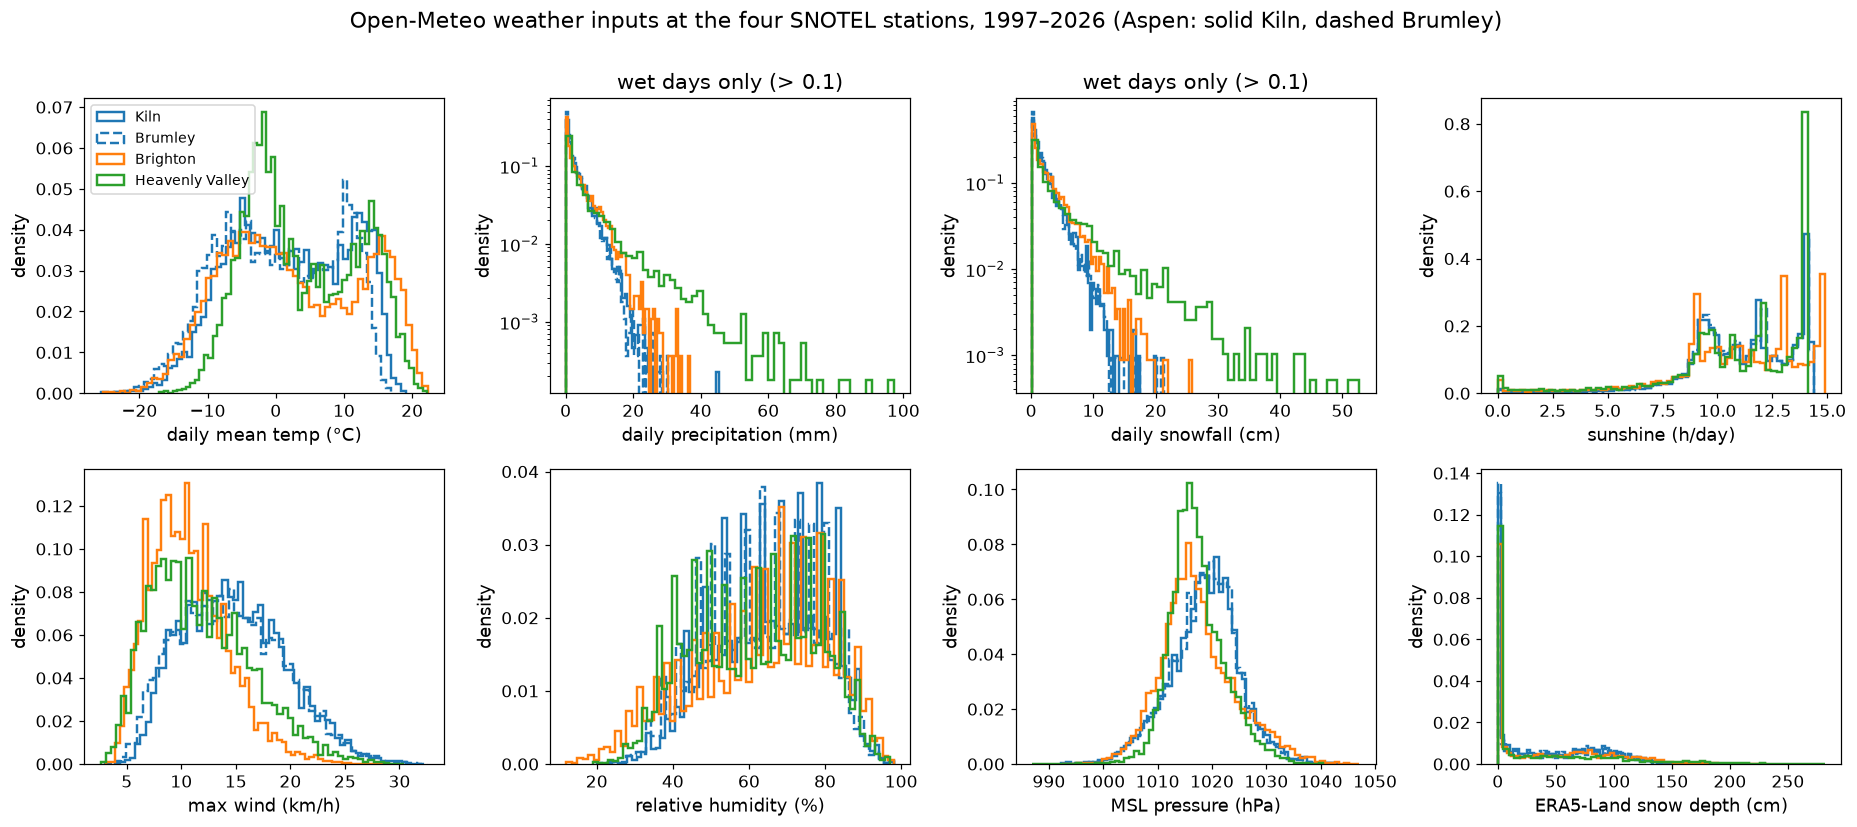

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, (c, lab) in zip(axes.flat, [("tmean", "daily mean temp (°C)"), ("precip", "daily precipitation (mm)"),
                                    ("snowfall", "daily snowfall (cm)"), ("sun_h", "sunshine (h/day)"),
                                    ("wind_max", "max wind (km/h)"), ("rh", "relative humidity (%)"),
                                    ("pmsl", "MSL pressure (hPa)"), ("land_sd", "ERA5-Land snow depth (cm)")]):
    for t, s in SI.items():
        x = s[c]
        if c in ("precip", "snowfall"):
            x = x[x > 0.1]
        ax.hist(x, bins=60, histtype="step", lw=1.6, density=True, label=meta.loc[t, "name"],
                color=COL[RESORT_OF[t]], ls="--" if t == "369:CO:SNTL" else "-")
    ax.set_xlabel(lab); ax.set_ylabel("density")
    if c in ("precip", "snowfall"):
        ax.set_yscale("log"); ax.set_title("wet days only (> 0.1)")
axes[0, 0].legend(fontsize=9)
fig.suptitle("Open-Meteo weather inputs at the four SNOTEL stations, 1997–2026 (Aspen: solid Kiln, dashed Brumley)", y=1.0)
fig.tight_layout(); savefig(fig, "weather_distributions"); plt.show()

In [11]:
top = []
for t, s in SI.items():
    for d_, v in s["precip"].nlargest(3).items():
        top.append({"station": meta.loc[t, "name"], "date": d_.date(), "ERA5 precip (mm)": v,
                    "ERA5 snowfall (cm)": s.loc[d_, "snowfall"], "ERA5 tmean (°C)": s.loc[d_, "tmean"]})
pd.DataFrame(top)

,station,date,ERA5 precip (mm),ERA5 snowfall (cm),ERA5 tmean (°C)
0,Kiln,2004-04-05,45.4,0.00,2.5
1,Kiln,2014-01-30,28.7,20.09,-3.5
2,Kiln,2009-05-22,28.0,0.00,5.5
3,Brumley,2014-01-30,30.4,21.28,-4.3
4,Brumley,2007-12-07,28.3,19.88,-4.0
5,Brumley,2023-04-25,26.6,17.08,-2.1
6,Brighton,2010-12-29,36.9,25.83,-7.6
7,Brighton,2004-10-20,34.2,0.77,1.6
8,Brighton,2012-01-21,32.9,21.91,-2.0
9,Heavenly Valley,2022-12-31,97.1,52.71,-2.3


**Reading the table.** Heavenly's three wettest days are all well-documented Sierra atmospheric-river storms:
- **2017-01-08**: the January 2017 AR that flooded the northern Sierra.
- **2021-10-24**: the record October 2021 "bomb cyclone" AR.
- **2022-12-31**: the New Year's Eve 2022 AR, the start of the record 2023 winter.

The two warm ones (tmean ≥ 0.4 °C) come out as mostly or entirely rain in ERA5. The cold one (2022-12-31, −2.3 °C) gives 53 cm of
snowfall. That is physically plausible and shows the dates are aligned. The Colorado and Utah extremes are ordinary large
mid-winter snowstorms (−2 to −8 °C), plus some spring and autumn rain events (e.g. Kiln 2004-04-05, 2009-05-22). Day-to-day
temperature swings are checked below.

In [12]:
rows = []
for t, s in SI.items():
    dT = s["tmean"].diff().abs()
    rows.append({"station": meta.loc[t, "name"], "max |Δ tmean| day-to-day (°C)": dT.max(), "date": dT.idxmax().date(),
                 "days with |Δ| > 10 °C": int((dT > 10).sum()), "99.9th pct |Δ| (°C)": round(dT.quantile(0.999), 1)})
pd.DataFrame(rows)

,station,max |Δ tmean| day-to-day (°C),date,days with |Δ| > 10 °C,99.9th pct |Δ| (°C)
0,Kiln,12.9,2008-12-14,23,10.9
1,Brumley,13.5,2017-11-18,16,10.5
2,Brighton,16.9,2020-09-08,17,10.5
3,Heavenly Valley,10.2,2003-10-30,1,7.9


Day-to-day swings above 10 °C are rare and fit Rocky Mountain cold-front passages. They are weather, not errors.
**Decision (D-030): no outlier removal or capping for the Open-Meteo inputs.** Every physical check passes, and the
extremes match real events. Removing them would delete exactly the storms that build the snowpack.

### 2.5 Consistency over time: are there artificial jumps?
A feature whose behaviour changes at some date for **non-weather** reasons (a new data source, a new sensor) breaks a model
trained on early winters and tested on late ones. Notebook 01 showed this for `best_match`, and we pinned the models (D-002).
Here we check the pinned series directly. For each winter (Nov–Apr) we plot the mean of three differences: **ERA5 − ERA5-Land**
temperature (two reanalyses), **SNOTEL − ERA5** temperature (station sensor against reanalysis), and the ratio of SNOTEL to ERA5
precipitation. A step in a difference series means one of its two sources changed.

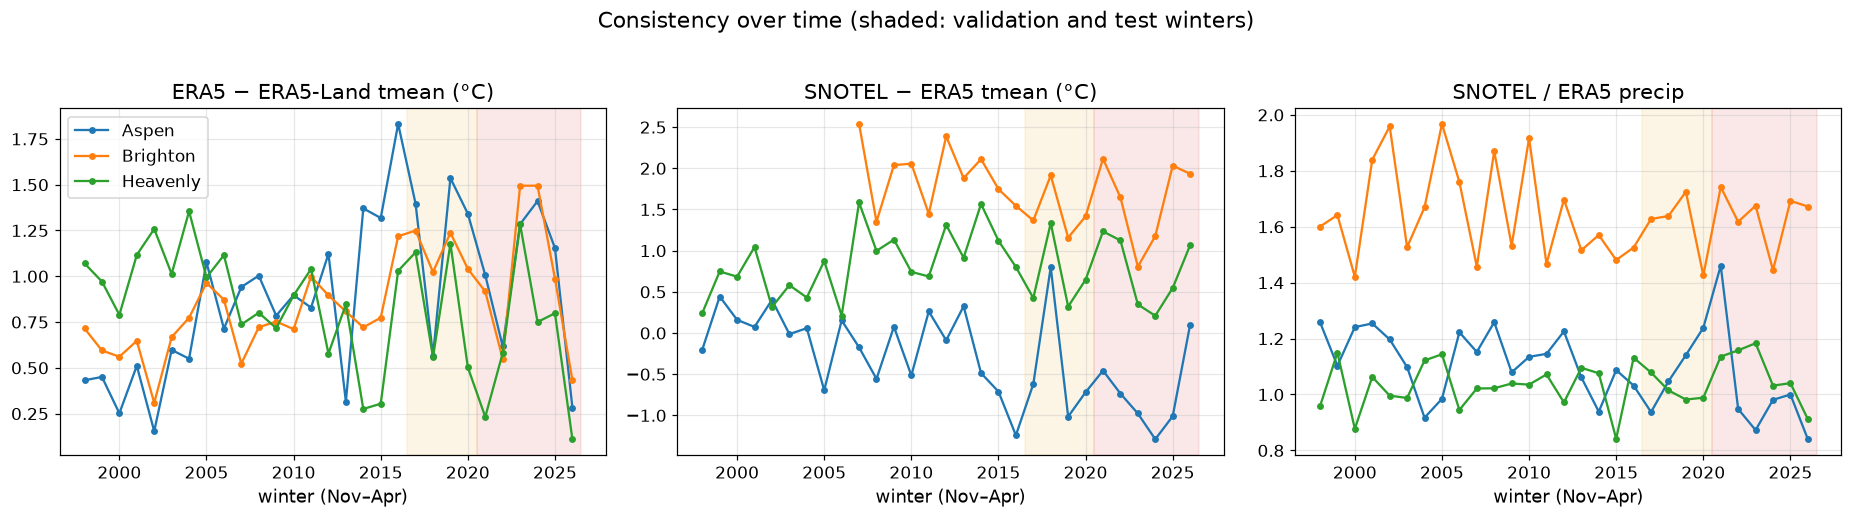

In [13]:
def comp_station_series(col, stations):
    f = pd.concat([clean[clean.station == t].set_index("date")[col] for t in stations], axis=1)
    return f.mean(axis=1).where(f.notna().all(axis=1))

W = {r: mt.resort_weather([F[t] for t in c["stations"]]) for r, c in RES.items()}   # resort-level weather (Aspen = mean)
H = []
for r, c in RES.items():
    w = W[r].copy()
    w["snotel_tavg"] = comp_station_series("TAVG_C", c["stations"]).reindex(w.index)
    w["snotel_prcp"] = comp_station_series("PRCP_mm", c["stations"]).reindex(w.index)
    w["winter"] = parse.winter_of(w.index)
    s = w[w.index.month.isin(mt.SEASON_MONTHS) & (w.winter.between(1998, 2026))]
    pr = s.dropna(subset=["snotel_prcp"])
    g = s.groupby("winter")
    H.append(pd.DataFrame({"resort": r,
                           "ERA5 − ERA5-Land tmean (°C)": g.apply(lambda x: (x.tmean - x.land_tmean).mean()),
                           "SNOTEL − ERA5 tmean (°C)": g.apply(lambda x: (x.snotel_tavg - x.tmean).mean()),
                           "SNOTEL / ERA5 precip": pr.groupby("winter").apply(lambda x: x.snotel_prcp.sum() / x.precip.sum()),
                           "SNOTEL tavg coverage": g.snotel_tavg.apply(lambda x: x.notna().mean())}))
H = pd.concat(H).reset_index()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharex=True)
for ax, col in zip(axes, ["ERA5 − ERA5-Land tmean (°C)", "SNOTEL − ERA5 tmean (°C)", "SNOTEL / ERA5 precip"]):
    for r, g in H.groupby("resort"):
        ax.plot(g.winter, g[col], "-o", ms=3.5, color=COL[r], label=r)
    ax.set_title(col); ax.set_xlabel("winter (Nov–Apr)"); ax.grid(alpha=.3)
    for lo, hi, n in [(2017, 2020, "val"), (2021, 2026, "test")]:
        ax.axvspan(lo - .5, hi + .5, color=SPLIT_COL[n], alpha=.10)
axes[0].legend()
fig.suptitle("Consistency over time (shaded: validation and test winters)", y=1.02)
fig.tight_layout(); savefig(fig, "homogeneity"); plt.show()

In [14]:
def step(col, split_year):
    out = {}
    for r, g in H.groupby("resort"):
        a, b = g[g.winter < split_year][col], g[g.winter >= split_year][col]
        out[r] = {"mean before": a.mean(), "mean after": b.mean(), "change": b.mean() - a.mean(),
                  "change / winter-to-winter SD": (b.mean() - a.mean()) / g[col].std()}
    return pd.DataFrame(out).T.round(3)
for col in ["ERA5 − ERA5-Land tmean (°C)", "SNOTEL − ERA5 tmean (°C)", "SNOTEL / ERA5 precip"]:
    print(f"\n{col}: before vs from 2021 (test winters)"); display(step(col, 2021))


ERA5 − ERA5-Land tmean (°C): before vs from 2021 (test winters)


,mean before,mean after,change,change / winter-to-winter SD
Aspen,0.869,0.959,0.090,0.205
Brighton,0.816,0.979,0.163,0.557
Heavenly,0.881,0.625,-0.256,-0.773



SNOTEL − ERA5 tmean (°C): before vs from 2021 (test winters)


,mean before,mean after,change,change / winter-to-winter SD
Aspen,-0.187,-0.729,-0.542,-0.989
Brighton,1.782,1.618,-0.164,-0.370
Heavenly,0.813,0.754,-0.059,-0.147



SNOTEL / ERA5 precip: before vs from 2021 (test winters)


,mean before,mean after,change,change / winter-to-winter SD
Aspen,1.120,1.017,-0.103,-0.722
Brighton,1.645,1.641,-0.004,-0.028
Heavenly,1.027,1.077,0.050,0.589


**Reading the plots and table.**
- **ERA5 − ERA5-Land temperature** wobbles by about ±0.5 °C from winter to winter, around a mean of about 0.9 °C, with **no
  step** like the `best_match` break in notebook 01. The test-period mean moves by −0.26 to +0.16 °C, under one winter-to-winter
  SD at every resort.
- **SNOTEL − ERA5 temperature:**
  - Brighton's SNOTEL temperature record starts only in 2007.
  - **Aspen drifts by about −1 °C from about 2013**: the test-period mean is 0.54 °C lower, about one SD. We can't tell from
    this alone whether the Kiln/Brumley sensors or ERA5 moved. But ERA5's own comparison with ERA5-Land shows no matching step,
    and SNOTEL sensors have documented changes (Oyler et al. 2015, *Int. J. Climatol.*). That is one more reason the model
    takes temperatures from Open-Meteo, not SNOTEL (D-021, D-031).
  - Milestone 3 should still check that the Aspen model's errors don't trend over the test winters.
- **SNOTEL / ERA5 precipitation:** Brighton's gauge collects about **1.6×** ERA5's precipitation. ERA5 smooths away the Wasatch's
  orographic enhancement. The ratio is stable over time (no change in the test period), so a per-resort model absorbs it.
  Aspen and Heavenly sit near 1.

### 2.6 How well do the weather inputs track what the station measured?
The model learns from the reanalysis, but the snowpack responds to the weather **at the station**. Agreement measures how
informative each input can be. The SNOTEL values here are the cleaned notebook 02 values, in-season (Nov–Apr) and measured.

In [15]:
rows = []
for r, c in RES.items():
    w = W[r].copy()
    w["tavg"] = comp_station_series("TAVG_C", c["stations"]).reindex(w.index)
    w["prcp"] = comp_station_series("PRCP_mm", c["stations"]).reindex(w.index)
    w["snwd"] = comp_station_series("SNWD_cm", c["stations"]).reindex(w.index)
    s = w[w.index.month.isin(mt.SEASON_MONTHS) & (parse.winter_of(w.index) >= c["first_winter"])]
    tt = s.dropna(subset=["tavg"])
    mon = s.dropna(subset=["prcp"]).resample("MS")[["prcp", "precip"]].sum(min_count=25).dropna()
    sd = s.dropna(subset=["snwd"])
    sd1 = pd.DataFrame({"snwd": s.snwd, "land_next": w.land_sd.shift(-1).reindex(s.index)}).dropna()
    rows.append({"resort": r,
                 "r(ERA5 tmean, SNOTEL tavg)": tt[["tmean", "tavg"]].corr().iloc[0, 1],
                 "bias ERA5 − SNOTEL (°C)": (tt.tmean - tt.tavg).mean(),
                 "r(ERA5-Land tmean, SNOTEL tavg)": tt[["land_tmean", "tavg"]].corr().iloc[0, 1],
                 "bias Land − SNOTEL (°C)": (tt.land_tmean - tt.tavg).mean(),
                 "r monthly precip": mon.corr().iloc[0, 1], "ERA5/SNOTEL monthly precip": mon.precip.sum() / mon.prcp.sum(),
                 "r(daily precip)": s.dropna(subset=["prcp"])[["prcp", "precip"]].corr().iloc[0, 1],
                 "r(Land depth t, SNWD t)": sd[["land_sd", "snwd"]].corr().iloc[0, 1],
                 "r(Land depth t+1, SNWD t)": sd1.corr().iloc[0, 1],
                 "Land depth / SNWD (means)": sd.land_sd.mean() / sd.snwd.mean()})
AGREE = pd.DataFrame(rows).set_index("resort").round(3)
AGREE

,"r(ERA5 tmean, SNOTEL tavg)",bias ERA5 − SNOTEL (°C),"r(ERA5-Land tmean, SNOTEL tavg)",bias Land − SNOTEL (°C),r monthly precip,ERA5/SNOTEL monthly precip,r(daily precip),"r(Land depth t, SNWD t)","r(Land depth t+1, SNWD t)",Land depth / SNWD (means)
resort,,,,,,,,,,
Aspen,0.942,0.414,0.948,-0.605,0.850,0.950,0.710,0.899,0.903,1.001
Brighton,0.865,-1.733,0.902,-2.660,0.882,0.610,0.773,0.940,0.943,0.747
Heavenly,0.877,-0.824,0.884,-1.638,0.967,0.962,0.877,0.960,0.960,0.638


**Reading the table.**
- **Temperature** agrees well day to day (r = 0.87–0.94 for ERA5, 0.88–0.95 for ERA5-Land). ERA5 − SNOTEL bias ranges from
  +0.4 °C (Aspen) to −1.7 °C (Brighton). It comes from the elevation correction and the sensor issues above. A constant bias
  does not hurt a per-resort model.
- **Daily precipitation** agrees much less than monthly. Storms are timed right but the amounts are smoothed, and gauges
  under-catch snow. Multi-day **sums** (7/30-day windows, §4) are therefore more informative than single days, which is why
  the features use them.
- **Daily precipitation:** ERA5 sees only 61 % of Brighton's gauge total (see §2.5), but 95–96 % at Aspen and Heavenly.
- **ERA5-Land snow depth** tracks the measured depth closely (r = 0.90–0.96). Its level is right at Aspen (ratio of means 1.00)
  but low at Brighton (0.75) and Heavenly (0.64), consistent with notebook 01 §3. It enters only as a **feature**, never as
  truth (D-005). Its correlation with SNWD is a little higher one day later, because SNWD
  dated *t* is the end-of-day reading (notebook 01 §3.3). The feature uses the day-*t* value, which is causal; the *t*+1 value
  would not be.

### 2.7 Are Kiln and Brumley really different weather inputs?
Aspen's weather inputs are the **mean of the two stations' requests** (`modeltable.resort_weather`). That only matters
if the two requests differ.

In [16]:
k, b = SI["556:CO:SNTL"], SI["369:CO:SNTL"]
print("grid cells:"); display(GRID[GRID.resort == "Aspen"][["station", "model", "grid lat/lon", "km from station"]])
pd.DataFrame({"r(Kiln, Brumley)": k.corrwith(b), "mean Kiln − Brumley": (k - b).mean(),
              "identical days (%)": ((k - b).abs() < 1e-9).mean() * 100}).round(3)

grid cells:


,station,model,grid lat/lon,km from station
2,Brumley,era5,"39.00, -106.50",10.4
3,Brumley,era5_land,"39.10, -106.50",3.9
6,Kiln,era5,"39.25, -106.50",12.4
7,Kiln,era5_land,"39.30, -106.70",7.6


,"r(Kiln, Brumley)",mean Kiln − Brumley,identical days (%)
tmax,0.998,1.556,0.302
tmin,0.983,1.598,0.963
tmean,0.997,1.710,0.406
precip,0.938,0.247,41.900
snowfall,0.921,0.026,68.004
sun_h,0.981,0.017,7.194
wind_max,0.965,0.273,3.758
cloud,0.984,1.468,13.170
rh,0.976,1.811,11.140
pmsl,0.998,0.100,9.111


Kiln and Brumley sit **in different grid cells in both models**: ERA5 cells 39.25 N vs 39.00 N, ERA5-Land cells 106.7 W vs
106.5 W. So the two requests carry partly independent information. Temperature is almost perfectly correlated (r ≈ 0.997), with
Kiln about 1.7 °C warmer (it is 293 m lower). Precipitation and snowfall correlate at r ≈ 0.92–0.94. They are identical mainly on
dry days (42 % / 68 % of days). The mean of the two is a slightly wider-area estimate, which fits a two-station composite target. **Decision (D-031):** Aspen weather is the mean of the member stations' requests. Each member is
requested at its own elevation, because that matches the fixed-membership composite target (D-008).

## 3. The target: measured snow depth per resort
`modeltable.resort_snotel` builds one daily series per resort from the clean table.
- **Brighton, Heavenly:** the single station's cleaned SNWD.
- **Aspen:** the **fixed-membership composite** (D-008). It is the mean of Kiln and Brumley **on days both have a value**,
  otherwise NaN, so the composition never changes over time. A day counts as **measured** only if neither member was imputed.
  Only measured days can be labels or evaluation truth (D-022).
  "Measured" means **an NRCS value we did not impute**. That includes values NRCS itself later edited (E) or estimated (K):
  NRCS's final value is the best available truth. The test winters are mostly still provisional, so their truth has had less
  NRCS review than older winters' (D-024).

In [17]:
S = {r: mt.resort_snotel(clean, c["stations"]) for r, c in RES.items()}
k = clean[clean.station == "556:CO:SNTL"].set_index("date").SNWD_cm
b = clean[clean.station == "369:CO:SNTL"].set_index("date").SNWD_cm
A = pd.DataFrame({"Kiln": k, "Brumley": b}).loc["2003-07-01":"2026-06-30"]
A = A[A.index.month.isin(mt.SEASON_MONTHS)]
A["winter"] = parse.winter_of(A.index)
cnt = pd.Series({
    "in-season days (winters 2004–2026)": len(A),
    "both present": int(A[["Kiln", "Brumley"]].notna().all(axis=1).sum()),
    "only Kiln": int((A.Kiln.notna() & A.Brumley.isna()).sum()),
    "only Brumley": int((A.Kiln.isna() & A.Brumley.notna()).sum()),
    "neither": int(A[["Kiln", "Brumley"]].isna().all(axis=1).sum()),
})
display(cnt.to_frame("days"))
both = A.dropna()
print(f"Kiln vs Brumley (both present): r = {both.Kiln.corr(both.Brumley):.3f}; "
      f"mean Kiln − Brumley = {(both.Kiln - both.Brumley).mean():+.1f} cm; "
      f"median |diff| = {(both.Kiln - both.Brumley).abs().median():.1f} cm")
print("winters where one member is missing on >5% of days (Brumley's sensor started part-way into winter 2004):",
      A.groupby("winter").apply(lambda g: g[["Kiln", "Brumley"]].isna().any(axis=1).mean()).loc[lambda s: s > .05].round(3).to_dict())

,days
in-season days (winters 2004–2026),4169
both present,4120
only Kiln,45
only Brumley,4
neither,0


Kiln vs Brumley (both present): r = 0.940; mean Kiln − Brumley = -2.9 cm; median |diff| = 7.6 cm
winters where one member is missing on >5% of days (Brumley's sensor started part-way into winter 2004): {2004: 0.192}


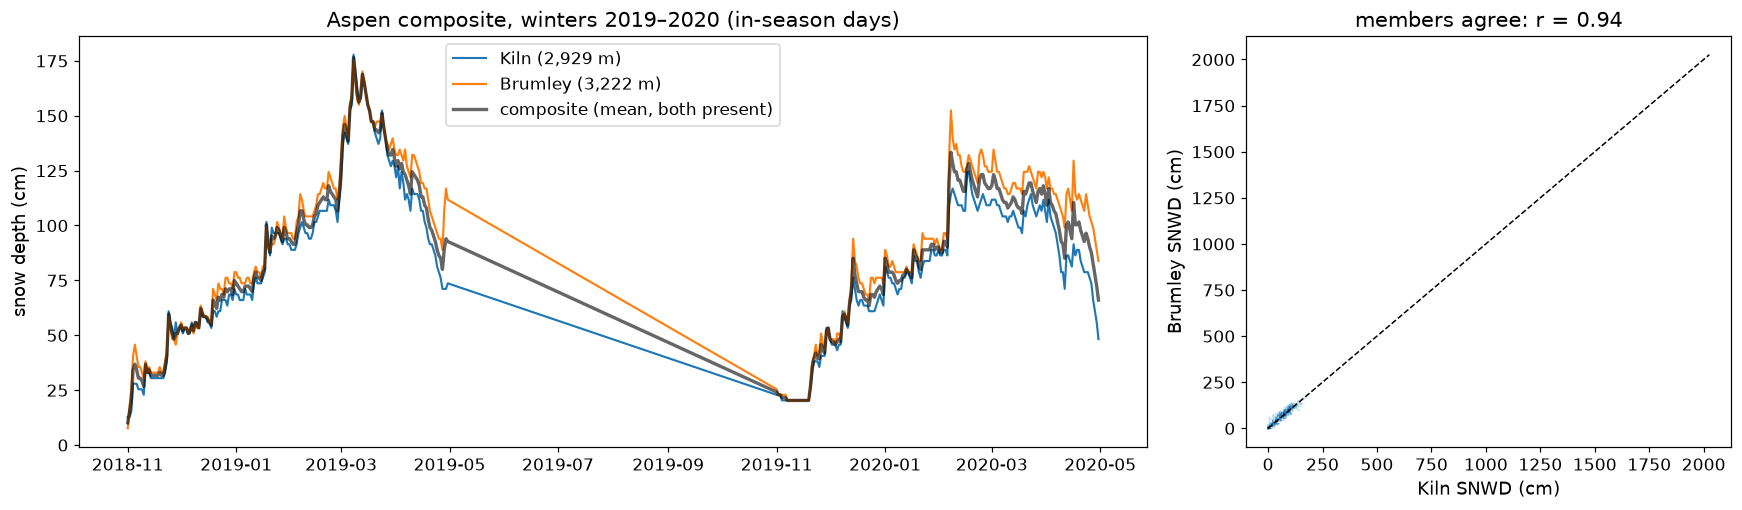

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
s = A.loc["2018-10-01":"2020-06-30"]
axes[0].plot(s.index, s.Kiln, lw=1.4, label="Kiln (2,929 m)"); axes[0].plot(s.index, s.Brumley, lw=1.4, label="Brumley (3,222 m)")
axes[0].plot(s.index, S["Aspen"].snwd.reindex(s.index), lw=2.2, color="k", alpha=.6, label="composite (mean, both present)")
axes[0].set_ylabel("snow depth (cm)"); axes[0].set_title("Aspen composite, winters 2019–2020 (in-season days)"); axes[0].legend()
axes[1].hexbin(both.Kiln, both.Brumley, gridsize=40, mincnt=1, cmap="Blues", bins="log")
lim = [0, both.max().max()]; axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set_xlabel("Kiln SNWD (cm)"); axes[1].set_ylabel("Brumley SNWD (cm)"); axes[1].set_title(f"members agree: r = {both.Kiln.corr(both.Brumley):.2f}")
fig.tight_layout(); savefig(fig, "aspen_composite"); plt.show()

### 3.1 Measured coverage per winter
For each resort and winter, the share of in-season days with a **measured** (non-imputed, all-members-present) depth.

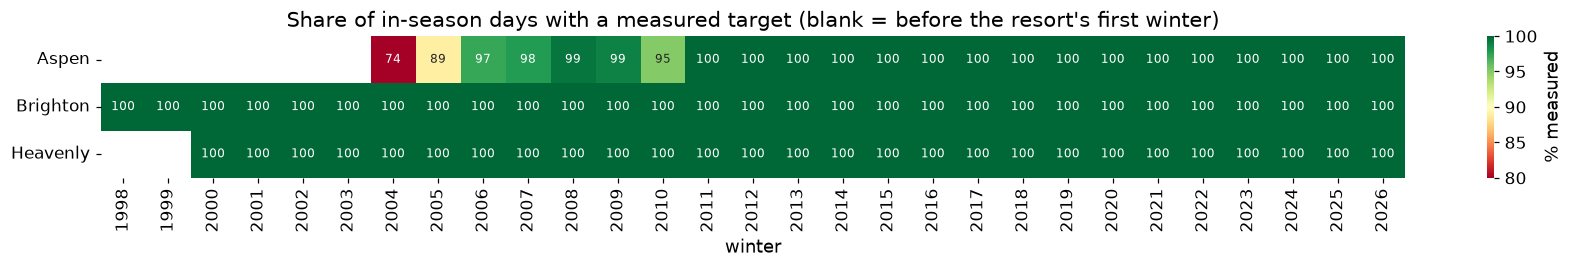

in-season days, measured / imputed / missing:


,Aspen,Brighton,Heavenly
measured,4081,5256,4894
imputed (feature-only),39,0,0
missing,49,0,0


In [19]:
cov = {}
for r, c in RES.items():
    s = S[r][S[r].index.month.isin(mt.SEASON_MONTHS)]
    s = s[parse.winter_of(s.index) >= c["first_winter"]]
    g = s.groupby(parse.winter_of(s.index))
    cov[r] = g.snwd_measured.mean() * 100
COV = pd.DataFrame(cov).loc[1998:2026]
fig, ax = plt.subplots(figsize=(16, 2.6))
sns.heatmap(COV.T, annot=True, fmt=".0f", cmap="RdYlGn", vmin=80, vmax=100, cbar_kws={"label": "% measured"}, ax=ax,
            annot_kws={"fontsize": 8})
ax.set_xlabel("winter"); ax.set_ylabel(""); ax.set_title("Share of in-season days with a measured target (blank = before the resort's first winter)")
fig.tight_layout(); plt.show()
print("in-season days, measured / imputed / missing:")
pd.DataFrame({r: {"measured": int(S[r].snwd_measured[(S[r].index.month.isin(mt.SEASON_MONTHS)) & (parse.winter_of(S[r].index) >= c["first_winter"])].sum()),
                  "imputed (feature-only)": int(S[r].snwd_imputed[(S[r].index.month.isin(mt.SEASON_MONTHS)) & (parse.winter_of(S[r].index) >= c["first_winter"])].sum()),
                  "missing": int(S[r].snwd.isna()[(S[r].index.month.isin(mt.SEASON_MONTHS)) & (parse.winter_of(S[r].index) >= c["first_winter"])].sum())}
              for r, c in RES.items()})

### 3.2 What the target looks like: seasonal curves of every winter
Each line is one winter's measured snow depth against day of the water year, coloured by the split proposed in §6. This is
the most important plot for the question. Winters differ hugely in **level and timing**, which is why a single
climatological curve has large errors. Within a winter, though, the depth is smooth, which is why persistence carries information.

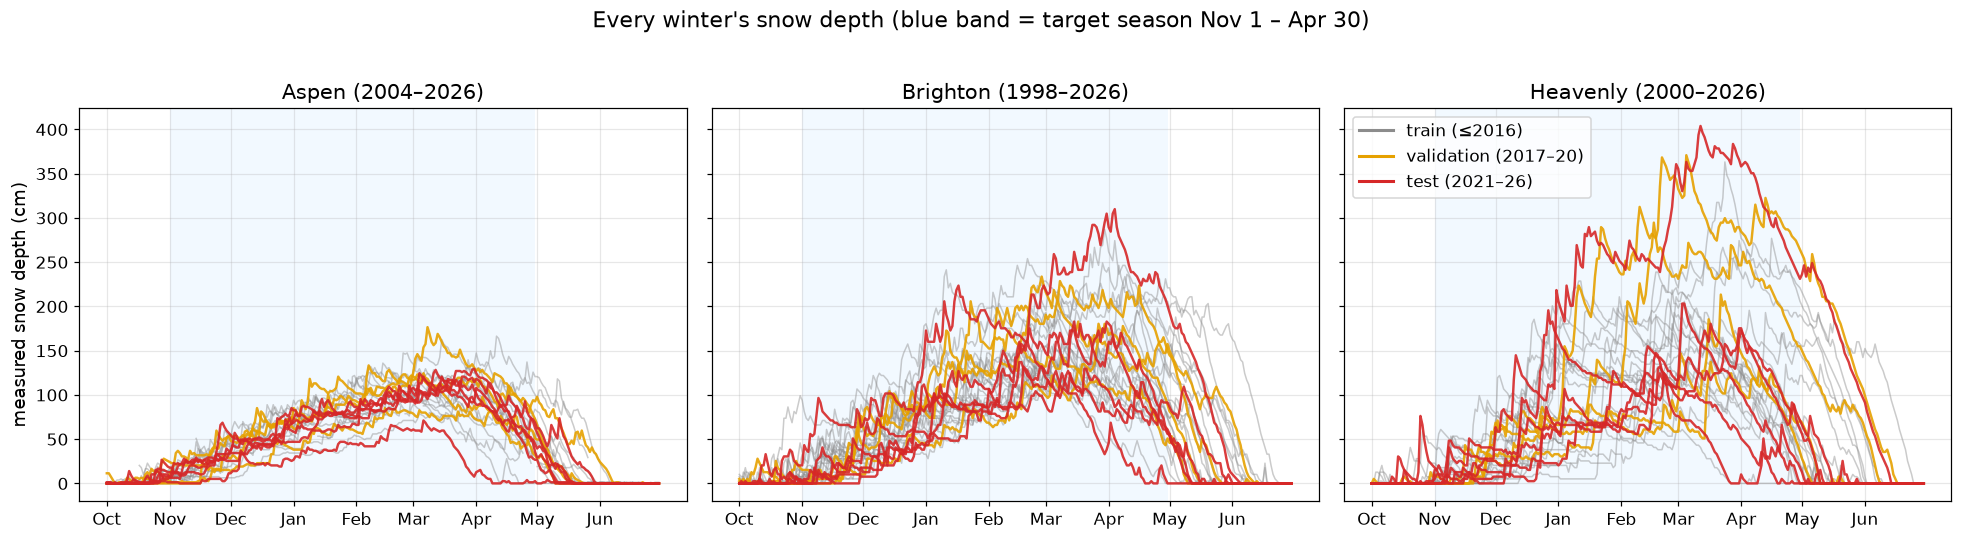

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, (r, c) in zip(axes, RES.items()):
    s = S[r].copy(); s["winter"] = parse.winter_of(s.index); s["dowy"] = mt.day_of_water_year(s.index)
    s = s[(s.dowy <= 272) & s.winter.between(c["first_winter"], sites.LAST_WINTER)]
    for wtr, g in s.groupby("winter"):
        sp = mt.split_of([wtr])[0]
        ax.plot(g.dowy, g.snwd.where(g.snwd_measured), lw=1.0 if sp == "train" else 1.6, color=SPLIT_COL[sp],
                alpha=.45 if sp == "train" else .9)
    ax.axvspan(31, 211, color="#cfe8ff", alpha=.25, lw=0)
    ax.set_xticks([0, 31, 61, 92, 123, 151, 182, 212, 243], ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun"])
    ax.set_title(f"{r} ({c['first_winter']}–{sites.LAST_WINTER})"); ax.grid(alpha=.3)
axes[0].set_ylabel("measured snow depth (cm)")
from matplotlib.lines import Line2D
axes[2].legend([Line2D([], [], color=SPLIT_COL[n], lw=2) for n in SPLIT_COL], ["train (≤2016)", "validation (2017–20)", "test (2021–26)"])
fig.suptitle("Every winter's snow depth (blue band = target season Nov 1 – Apr 30)", y=1.02)
fig.tight_layout(); savefig(fig, "seasonal_curves"); plt.show()

## 4. Features: what a forecaster knows at the end of day *t*
The resort-level daily frame joins the weather inputs (§2) and the SNOTEL series (§3) on date.
`modeltable.build_features` then computes every feature **from rows dated ≤ *t* only**, using backward differences, trailing
windows and running totals since Oct 1. Trailing windows are **strict**: one missing day in the window makes the feature NaN,
never a partial sum that would silently mean something different.

In [21]:
D = {}
for r in RES:
    d = W[r].join(S[r], how="left").loc[features.FEATURE_START:features.FEATURE_END]
    assert len(d) == len(pd.date_range(features.FEATURE_START, features.FEATURE_END)), "weather calendar must be complete"
    D[r] = d
FE = {r: mt.build_features(d) for r, d in D.items()}
print({r: f.shape for r, f in FE.items()})

{'Aspen': (10592, 54), 'Brighton': (10592, 54), 'Heavenly': (10592, 54)}


In [22]:
CAT = [  # (regex, group, source, definition, unit)
    (r"^dowy$", "calendar", "—", "days since Oct 1 of the water year, at issue date t", "d"),
    (r"^target_dowy$", "calendar", "—", "dowy + 30 (the target's day of season; known in advance)", "d"),
    (r"^doy_(sin|cos)$", "calendar", "—", "sin/cos of 2π·day-of-year/365.25", "—"),
    (r"^snwd_t$", "snow state", "SNOTEL", "snow depth at end of day t (cleaned; ≤3-day causal fill allowed)", "cm"),
    (r"^wteq_t$", "snow state", "SNOTEL", "snow-water equivalent at end of day t", "cm"),
    (r"^snwd_t_imputed$", "snow state", "SNOTEL", "1 if snwd_t was forward-filled (D-022)", "0/1"),
    (r"^d_snwd_(\d+)$", "snow state", "SNOTEL", "snwd_t − snwd_(t−k)", "cm"),
    (r"^d_wteq_(\d+)$", "snow state", "SNOTEL", "wteq_t − wteq_(t−k)", "cm"),
    (r"^prcp_sum_(\d+)$", "snow state", "SNOTEL", "station precipitation, sum over t−k+1..t (strict)", "mm"),
    (r"^snwd_peak_wy$", "snow state", "SNOTEL", "max snow depth from Oct 1 to t", "cm"),
    (r"^wteq_peak_wy$", "snow state", "SNOTEL", "max SWE from Oct 1 to t", "cm"),
    (r"^(tmax|tmin|tmean)_t$", "weather, day t", "ERA5", "day-t temperature", "°C"),
    (r"^snowfall_t$", "weather, day t", "ERA5", "day-t snowfall (precip partitioned as snow, 0.7 cm/mm)", "cm"),
    (r"^precip_t$", "weather, day t", "ERA5", "day-t precipitation", "mm"),
    (r"^pmsl_t$", "weather, day t", "ERA5", "day-t mean sea-level pressure", "hPa"),
    (r"^d_pmsl_3$", "weather, day t", "ERA5", "pressure tendency pmsl_t − pmsl_(t−3)", "hPa"),
    (r"^(precip|snowfall|sun_h)_sum_(\d+)$", "weather, trailing", "ERA5", "sum over t−k+1..t", "mm / cm / h"),
    (r"^pdd_sum_(\d+)$", "weather, trailing", "ERA5", "positive degree-days Σ max(tmean, 0) over t−k+1..t (melt proxy)", "°C·d"),
    (r"^(tmean|tmax|tmin|wind_max|cloud|rh|pmsl)_mean_(\d+)$", "weather, trailing", "ERA5", "mean over t−k+1..t", "°C / km/h / % / hPa"),
    (r"^(snowfall|precip|pdd)_wy$", "weather, season-to-date", "ERA5", "running total from Oct 1 to t", "cm / mm / °C·d"),
    (r"^land_sd_t$", "reanalysis snow", "ERA5-Land", "modelled snow depth on day t (feature only, never truth)", "cm"),
    (r"^d_land_sd_(\d+)$", "reanalysis snow", "ERA5-Land", "land_sd_t − land_sd_(t−k)", "cm"),
    (r"^land_tmean_mean_7$", "reanalysis snow", "ERA5-Land", "7-day mean ERA5-Land temperature (0.1° grid)", "°C"),
    (r"^rob_snwd_t$", "robustness (D-024)", "SNOTEL original", "snwd_t from NRCS ORIGINAL (pre-edit) readings; causal QC only (bounds, D-020 negatives, recursive trailing spike rule)", "cm"),
    (r"^rob_d_snwd_(\d+)$", "robustness (D-024)", "SNOTEL original", "change in original readings over k days", "cm"),
]
def describe(col):
    for pat, grp, src, dfn, unit in CAT:
        m_ = re.match(pat, col)
        if m_:
            k_ = next((g for g in m_.groups() if g and g.isdigit()), None)
            return grp, src, dfn.replace("k", k_) if (k_ and "k" in dfn) else dfn, unit
    raise KeyError(col)
FCOLS = list(FE["Aspen"].columns)
FEAT_CAT = pd.DataFrame([(c, *describe(c)) for c in FCOLS], columns=["feature", "group", "source", "definition", "unit"])
print(f"{len(FCOLS)} feature columns; by group:", FEAT_CAT.group.value_counts().to_dict())
FEAT_CAT

54 feature columns; by group: {'weather, trailing': 22, 'snow state': 11, 'weather, day t': 7, 'calendar': 4, 'reanalysis snow': 4, 'weather, season-to-date': 3, 'robustness (D-024)': 3}


,feature,group,source,definition,unit
0,dowy,calendar,—,"days since Oct 1 of the water year, at issue d...",d
1,target_dowy,calendar,—,dowy + 30 (the target's day of season; known i...,d
2,doy_sin,calendar,—,sin/cos of 2π·day-of-year/365.25,—
3,doy_cos,calendar,—,sin/cos of 2π·day-of-year/365.25,—
4,snwd_t,snow state,SNOTEL,snow depth at end of day t (cleaned; ≤3-day ca...,cm
5,wteq_t,snow state,SNOTEL,snow-water equivalent at end of day t,cm
6,snwd_t_imputed,snow state,SNOTEL,1 if snwd_t was forward-filled (D-022),0/1
7,d_snwd_7,snow state,SNOTEL,snwd_t − snwd_(t−7),cm
8,d_wteq_7,snow state,SNOTEL,wteq_t − wteq_(t−7),cm
9,prcp_sum_7,snow state,SNOTEL,"station precipitation, sum over t−7+1..t (strict)",mm


**Design choices** (D-031)
- **Two windows, 7 and 30 days.** These are the recent-storm and recent-month scales. With about 2,400–3,400 training rows per
  resort, but only 13–19 independent winters, a compact, interpretable set suits linear regression; the random forest can
  combine features itself. Feature selection is Milestone 3 work.
- **Temperatures come from Open-Meteo, not SNOTEL.** SNOTEL temperatures carry the sensor-change bias (§2.5), and one of their
  cleaning rules looks ahead (the stuck-sensor rule needs the whole run, §4.3).
- **No weather after day *t*.** Open-Meteo has no archived 30-day forecasts (D-004), so a real-time forecaster would not know
  the weather of *t*+1 … *t*+30. The model has to rely on the snowpack state plus climatology.
- **`rob_*` columns** exist only for the D-024 robustness run (§9). They are excluded from the main feature set.

### 4.1 Feature missingness
Weather features are complete by construction (§2.2). NaN comes from SNOTEL gaps propagated through strict windows, and from
the start of each record (no history before 1997-07-01).

In [23]:
miss = pd.DataFrame({r: f[f.index.month.isin([10, 11, 12, 1, 2, 3])].loc[f"{RES[r]['first_winter']-1}-10-01":].isna().mean() * 100
                     for r, f in FE.items()})
miss = miss[miss.max(axis=1) > 0].sort_values("Aspen", ascending=False).round(2)
print("% NaN on issue dates Oct–Mar of each resort's modelled winters (features with any NaN only):")
miss

% NaN on issue dates Oct–Mar of each resort's modelled winters (features with any NaN only):


,Aspen,Brighton,Heavenly
rob_d_snwd_30,21.14,17.11,2.17
rob_d_snwd_7,20.30,15.76,1.97
rob_snwd_t,12.09,9.10,1.02
prcp_sum_30,5.53,0.00,0.00
prcp_sum_7,4.39,0.00,0.00
d_snwd_30,2.31,0.68,0.00
d_snwd_7,1.72,0.25,0.00
snwd_t,1.17,0.11,0.00
snwd_peak_wy,1.17,0.11,0.00


### 4.2 Leakage audit on the real data
The unit tests prove causality on synthetic data. Here we re-check it on the actual resort frames, two independent ways, for
40 random issue dates per resort:
1. **Truncation.** Recompute the features using only the data up to *t* (`D[r].loc[:t]`) and compare them with the
   full-data row for *t*.
2. **Future perturbation.** Overwrite every value after *t* with nonsense and recompute. No feature dated ≤ *t* may change.

In [24]:
rng = np.random.default_rng(109)
rows = []
for r, d in D.items():
    full = FE[r]
    dates = pd.DatetimeIndex(rng.choice(full.loc[f"{RES[r]['first_winter']-1}-10-02":"2026-03-31"].index, 40, replace=False))
    trunc_max = 0.0
    for t in dates:
        cut = mt.build_features(d.loc[:t]).loc[t]
        diff = (cut.astype(float) - full.loc[t].astype(float)).abs()
        assert ((cut.isna() == full.loc[t].isna()).all()), (r, t)
        trunc_max = max(trunc_max, float(diff.max(skipna=True)) if diff.notna().any() else 0.0)
    pert_max = 0.0
    for t in dates[:10]:
        d2 = d.copy(); fut = d2.index > t
        for c in d2.columns:
            if d2[c].dtype.kind == "f":
                d2.loc[fut, c] = rng.normal(1e4, 1e3, fut.sum())
        a, b_ = full.loc[:t], mt.build_features(d2).loc[:t]
        same_nan = (a.isna() == b_.isna()).all().all()
        pert_max = max(pert_max, float((a - b_).abs().max().max()) if same_nan else np.inf)
    rows.append({"resort": r, "issue dates tested (truncation)": len(dates), "max |Δ| truncation": trunc_max,
                 "issue dates tested (perturbation)": 10, "max |Δ| perturbation": pert_max})
LEAK = pd.DataFrame(rows)
assert (LEAK["max |Δ| truncation"] < 1e-9).all() and (LEAK["max |Δ| perturbation"] < 1e-9).all()
LEAK

,resort,issue dates tested (truncation),max |Δ| truncation,issue dates tested (perturbation),max |Δ| perturbation
0,Aspen,40,0.0,10,0.0
1,Brighton,40,0.0,10,0.0
2,Heavenly,40,0.0,10,0.0


Both checks give **exactly zero** difference. **Given the cleaned daily inputs**, no feature can see past its issue date.
These checks cannot detect look-ahead that happened *upstream*, in notebook 02's cleaning or in NRCS's own later edits,
because they perturb the already-cleaned frame. §4.3 quantifies that separately.

### 4.3 Look-ahead in upstream cleaning steps
`build_features` is causal, but its inputs come from notebook 02, and some cleaning rules use more than day *t*. We list
every such rule and measure how much it touches **these four stations' snow-state features** over the modelled period
(winters 1998–2026, issue dates Oct–Apr).

In [25]:
c4 = clean[clean.station.isin(STATIONS) & clean.winter.between(1998, 2026) & clean.date.dt.month.isin([10, 11, 12, 1, 2, 3, 4])]
def flagged(col, rule):
    return int(c4[f"{col}_clean_flag"].fillna("").str.contains(rule, regex=False).sum())
edited = (c4.SNWD_cm.notna() & c4.SNWD_nrcs_orig.notna() & ((c4.SNWD_cm - c4.SNWD_nrcs_orig * 2.54).abs() > 0.01))
UP = pd.DataFrame([
    ("centred 7-day spike rule (D-017)", "uses days t−3..t+3 to judge day t", "SNWD/WTEQ", flagged("SNWD", "spike") + flagged("WTEQ", "spike"),
     "none needed (0 rows at these stations)"),
    ("≤3-day gap forward fill (D-022)", "whether a gap qualifies depends on when it ends", "SNWD/WTEQ", int(c4.SNWD_imputed.sum() + c4.WTEQ_imputed.sum()),
     "values are past-only; imputed targets never labels"),
    ("density > 1 rule (D-018)", "same day only", "SNWD", flagged("SNWD", "density"), "causal — none"),
    ("stuck-sensor rule, temperatures (D-021)", "needs the whole ≥5-day run", "TAVG/TMAX/TMIN", flagged("TAVG", "stuck") + flagged("TMAX", "stuck") + flagged("TMIN", "stuck"),
     "SNOTEL temperatures not used as features"),
    ("NRCS S (suspect) removal (D-016)", "NRCS judgement, possibly made later", "SNWD", int(c4.SNWD_nrcs_qc.astype("string").eq("S").sum()),
     "rob_* features use originals (§9)"),
    ("NRCS edits to values (D-024)", "edits made weeks–months later", "SNWD", int(edited.sum()), "rob_* robustness run (§9)"),
], columns=["upstream step", "why it is not strictly causal", "variables", "rows affected (4 stations, Oct–Apr, 1998–2026)", "mitigation"])
UP

,upstream step,why it is not strictly causal,variables,"rows affected (4 stations, Oct–Apr, 1998–2026)",mitigation
0,centred 7-day spike rule (D-017),uses days t−3..t+3 to judge day t,SNWD/WTEQ,0,none needed (0 rows at these stations)
1,≤3-day gap forward fill (D-022),whether a gap qualifies depends on when it ends,SNWD/WTEQ,48,values are past-only; imputed targets never la...
2,density > 1 rule (D-018),same day only,SNWD,0,causal — none
3,"stuck-sensor rule, temperatures (D-021)",needs the whole ≥5-day run,TAVG/TMAX/TMIN,0,SNOTEL temperatures not used as features
4,NRCS S (suspect) removal (D-016),"NRCS judgement, possibly made later",SNWD,85,rob_* features use originals (§9)
5,NRCS edits to values (D-024),edits made weeks–months later,SNWD,3224,rob_* robustness run (§9)


Notes on the table:
- The SNOTEL **stuck-sensor** temperature rule fired at these stations only in winters 1986–1991, so it touches 0 modelled rows.
- The temperature **spike** flags likewise affect only SNOTEL temperatures, which are not features.
- The ≤3-day fill touched 48 values. Imputed **targets** are already excluded from labels: `y` is NaN unless measured. The
  fill's *values* are past-only, but *whether* a gap is filled depends on whether the series resumes within 3 days. So for
  those 48 rows, the fact that `snwd_t` is present (and the `snwd_t_imputed` flag) carries a little future information about
  missingness. A strictly causal alternative is `ffill(limit=3)` on every gap. D-022 accepted the current rule, and the effect is
  negligible at this scale.

Two more availability caveats are recorded as decisions:
- **Reanalysis latency (D-034).** ERA5 is published about 5 days behind real time, so an operational forecaster would not have
  day-*t* reanalysis on day *t*. Our study is a **hindcast**: "weather through day *t*" stands in for what a forecast system's
  own analysis would know. Milestone 3 should include a sensitivity run with weather features lagged 5 days.
- **Climatology** is fitted on training winters only (§7). It is not a column in the saved table, because its values depend on
  which winters are "training". It is recomputed inside every split.

## 5. Labels and the modelling table
`modeltable.labels` is the **only** place in the project that looks ahead: it reads SNWD on date *t* + 30. A row enters
the table if its **target date** falls in **Nov 1 – Apr 30** (D-029), so issue dates run from Oct 2 to Mar 31. The issue date
and target date always fall in the same winter, which the code asserts. A row is a **usable label** only if the target is
measured (not imputed, every member present).

In [26]:
T = pd.concat([mt.model_table(D[r], r, c["first_winter"], sites.LAST_WINTER) for r, c in RES.items()])
print("modelling table:", T.shape, f"| {T.memory_usage(deep=True).sum()/1e6:.1f} MB in memory")
print("issue dates:", T.index.min().date(), "→", T.index.max().date(), "| target dates:", T.target_date.min().date(), "→", T.target_date.max().date())
print("issue-date months:", sorted(T.index.month.unique()), "| target-date months:", sorted(T.target_date.dt.month.unique()))
BASE = [c for c in FCOLS if not c.startswith("rob_")]
fun = []
for r, g in T.groupby("resort", sort=False):
    a = g; b_ = a[a.y_measured]; c_ = b_[b_.snwd_t.notna()]; d_ = c_.dropna(subset=BASE)
    fun.append({"resort": r, "winters": g.winter.nunique(), "1. issue dates (target Nov–Apr)": len(a),
                "2. target measured": len(b_), "3. + snow depth known at t": len(c_), "4. + every main feature present": len(d_),
                "kept at step 4 (%)": round(100 * len(d_) / len(a), 1)})
FUNNEL = pd.DataFrame(fun).set_index("resort"); FUNNEL.loc["total"] = FUNNEL.sum(numeric_only=True); FUNNEL.loc["total", "kept at step 4 (%)"] = round(100 * FUNNEL.loc["total", "4. + every main feature present"] / FUNNEL.loc["total", "1. issue dates (target Nov–Apr)"], 1)
FUNNEL

modelling table: (14319, 60) | 7.1 MB in memory
issue dates: 1997-10-02 → 2026-03-31 | target dates: 1997-11-01 → 2026-04-30
issue-date months: [1, 2, 3, 10, 11, 12] | target-date months: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(11), np.int32(12)]


,winters,1. issue dates (target Nov–Apr),2. target measured,3. + snow depth known at t,4. + every main feature present,kept at step 4 (%)
resort,,,,,,
Aspen,23,4169,4081,4036,3747,89.9
Brighton,29,5256,5256,5251,5221,99.3
Heavenly,27,4894,4894,4894,4894,100.0
total,79,14319,14231,14181,13862,96.8


**Row accounting.** Steps 2–4 drop rows; nothing is imputed to keep them.
- Step 2 drops targets that are missing or imputed.
- Step 3 drops issue dates without a snow reading.
- Step 4 is the complete-case set for models that cannot handle NaN, such as linear regression. Most step-4 losses come from
  SNOTEL precipitation gaps (`prcp_sum_*`). Milestone 3 can drop those features or add missingness indicators, as an
  explicit, documented choice.

In [27]:
print("dtypes:", T.dtypes.value_counts().to_dict())
T[["resort", "winter", "split", "target_date", "y", "y_measured", "snwd_t", "wteq_t", "d_snwd_30", "snowfall_sum_30",
   "pdd_sum_30", "tmean_mean_7", "land_sd_t"]].groupby("resort").describe().T.round(1).head(60)

dtypes: {dtype('float64'): 53, dtype('int64'): 3, <StringDtype(na_value=nan)>: 2, dtype('<M8[us]'): 1, dtype('bool'): 1}


resort                                      Aspen             Brighton                    Heavenly
winter          count                      4169.0               5256.0                      4894.0
                mean                  2014.998561               2012.0                  2012.99857
                min                        2004.0               1998.0                      2000.0
                25%                        2009.0               2005.0                      2006.0
                50%                        2015.0               2012.0                      2013.0
                75%                        2021.0               2019.0                      2020.0
                max                        2026.0               2026.0                      2026.0
                std                      6.634443             8.366919                    7.790075
target_date     count                        4169                 5256                        4894
                mean   2015-01-29 17:38:40.268649  2012-01-30 12:00:00  2013-01-29 05:41:01.299550
                min           2003-11-01 00:00:00  1997-11-01 00:00:00         1999-11-01 00:00:00
                25%           2009-03-16 00:00:00  2004-12-15 18:00:00         2006-03-16 06:00:00
                50%           2015-01-30 00:00:00  2012-01-30 12:00:00         2013-01-29 12:00:00
                75%           2020-12-15 00:00:00  2019-03-16 06:00:00         2019-12-15 18:00:00
                max           2026-04-30 00:00:00  2026-04-30 00:00:00         2026-04-30 00:00:00
                std                           NaN                  NaN                         NaN
y               count                      4081.0               5256.0                      4894.0
                mean                    68.996694            98.686442                   97.640008
                min                           0.0                  0.0                         0.0
                25%                         43.18                53.34                       33.02
                50%                         72.39                93.98                       81.28
                75%                         95.25               134.62                      137.16
                max                        176.53               309.88                      403.86
                std                     35.072085            58.904537                   78.307141
snwd_t          count                      4120.0               5251.0                      4894.0
                mean                    56.900007            78.485081                    78.00094
                min                           0.0                  0.0                         0.0
                25%                         17.78                20.32                        7.62
                50%                         59.69                78.74                       60.96
                75%                          88.9               121.92                      124.46
                max                        176.53                304.8                      403.86
                std                     40.312175            62.164934                   77.781811
wteq_t          count                      4169.0               5256.0                      4894.0
                mean                    12.596182            23.234766                   24.926358
                min                           0.0                  0.0                         0.0
                25%                         3.429                4.572                       2.032
                50%                        11.049               19.812                      18.034
                75%                        19.558               36.322                      39.624
                max                        43.942              103.378                     146.812
                std                     

## 6. Train / validation / test split by winter
**Proposal (D-032).** One calendar split for all three resorts:

| split | winters (season-end year) | used for |
|---|---|---|
| **train** | first winter … 2016 | fitting models, climatology, scalers |
| **validation** | 2017–2020 | model and hyper-parameter choice (or expanding-window CV within train + validation) |
| **test** | 2021–2026 | **touched once**, after all choices are frozen. Final models are refit on train + validation |

Why this split:
1. The staff require it: test on **later** winters, never random (condition 3).
2. A **common calendar** means every resort is tested on the same winters, so comparisons between resorts aren't confounded by
   which years each one got.
3. Six test winters give 1,087 test rows per resort and, more importantly, **six independent seasons**. We check below that they
   include both big and lean years.
4. Splitting at winter boundaries means no 30-day target window crosses a split: a summer separates every pair of winters.

In [28]:
SPL = (T.groupby(["resort", "split"]).agg(winters=("winter", "nunique"), first=("winter", "min"), last=("winter", "max"),
                                          rows=("y", "size"), usable_labels=("y_measured", "sum"))
       .reindex(["train", "val", "test"], level=1))
SPL["share of rows (%)"] = (100 * SPL.rows / SPL.groupby(level=0).rows.transform("sum")).round(1)
SPL

winters  first  last  rows  usable_labels  share of rows (%)
resort   split                                                              
Aspen    train       13   2004  2016  2357           2269               56.5
         val          4   2017  2020   725            725               17.4
         test         6   2021  2026  1087           1087               26.1
Brighton train       19   1998  2016  3444           3444               65.5
         val          4   2017  2020   725            725               13.8
         test         6   2021  2026  1087           1087               20.7
Heavenly train       17   2000  2016  3082           3082               63.0
         val          4   2017  2020   725            725               14.8
         test         6   2021  2026  1087           1087               22.2

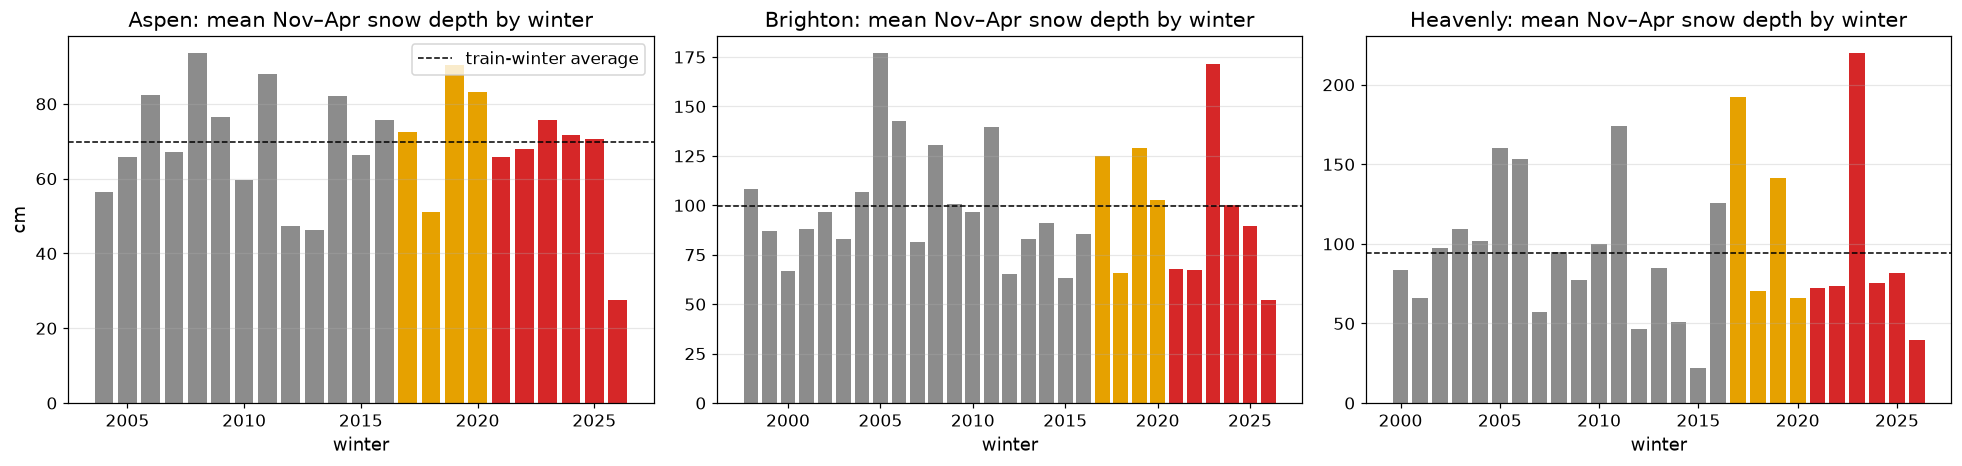

test-winter ranks (mean depth) per resort:


resort,Aspen,Brighton,Heavenly
winter,,,
2021,16,23,19
2022,13,24,18
2023,9,2,1
2024,11,12,17
2025,12,16,15
2026,23,29,26


In [29]:
peak = []
for r, c in RES.items():
    s = S[r][S[r].snwd_measured & S[r].index.month.isin(mt.SEASON_MONTHS)]
    g = s.groupby(parse.winter_of(s.index)).snwd
    peak.append(pd.DataFrame({"resort": r, "peak": g.max(), "mean": g.mean()}).loc[c["first_winter"]:sites.LAST_WINTER])
PEAK = pd.concat(peak).rename_axis("winter").reset_index()
PEAK["split"] = mt.split_of(PEAK.winter)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4), sharey=False)
for ax, (r, g) in zip(axes, PEAK.groupby("resort", sort=False)):
    ax.bar(g.winter, g["mean"], color=[SPLIT_COL[s] for s in g.split])
    ax.axhline(g[g.split == "train"]["mean"].mean(), color="k", ls="--", lw=1, label="train-winter average")
    ax.set_title(f"{r}: mean Nov–Apr snow depth by winter"); ax.set_xlabel("winter"); ax.grid(alpha=.3, axis="y")
axes[0].set_ylabel("cm"); axes[0].legend()
fig.tight_layout(); savefig(fig, "split_winters"); plt.show()
PEAK["rank among all winters (1 = deepest)"] = PEAK.groupby("resort")["mean"].rank(ascending=False).astype(int)
print("test-winter ranks (mean depth) per resort:")
PEAK[PEAK.split == "test"].pivot(index="winter", columns="resort", values="rank among all winters (1 = deepest)")

In [30]:
cmp_ = PEAK.groupby(["resort", "split"])["mean"].agg(["mean", "std", "min", "max"]).reindex(["train", "val", "test"], level=1).round(1)
cmp_

mean   std   min    max
resort   split                          
Aspen    train   69.8  14.9  46.3   93.5
         val     74.3  17.2  51.0   90.4
         test    63.2  17.8  27.6   75.6
Brighton train   99.6  29.4  63.1  176.8
         val    105.5  28.9  65.8  129.0
         test    91.3  42.8  52.1  171.4
Heavenly train   94.4  41.6  21.7  173.8
         val    117.5  60.6  65.8  192.3
         test    93.7  63.4  39.6  219.6

**Reading these.**
- **The test winters span both extremes.** Ranks are by mean Nov–Apr depth:
  - **2023** is the deepest winter on record at Heavenly, 2nd at Brighton and 9th of 23 at Aspen.
  - **2026** (the 2025–26 season) is the **shallowest on record** at Aspen and Brighton, and 26th of 27 at Heavenly.
  - 2021–2022 were also lean, especially at Brighton (23rd–24th of 29).
- **Distribution shift.** The test-winter mean depth is lower than the training mean at Aspen (63 vs 70 cm) and Brighton
  (91 vs 100 cm), and about equal at Heavenly (94 vs 94 cm). Test winters are also **more variable** (SD 18–63 vs 15–42 cm).
  So the climatology baseline over-predicts on average in the test winters (bias +5 to +9 cm, §7), and the models face the
  same harder, more extreme years. This is what a time-based split is meant to expose, and we should say so in the
  presentation rather than hide it.

### 6.1 Why a random split would leak
Consecutive days in one winter are almost duplicates. Day *t*'s target (depth at *t* + 30) is nearly the same as day *t* + 1's.
A random split puts near-copies of test rows in the training set. We show this two ways, using **train + validation winters
only**, so the test winters stay untouched:
(a) the autocorrelation of the target from day to day, and (b) the same ridge regression scored with a shuffled 5-fold split
and with a grouped-by-winter 5-fold split.

,rows,winters,"MAE, random 5-fold (cm)","MAE, grouped by winter (cm)",random split makes the error look smaller by (%)
resort,,,,,
Aspen,2841,17,11.3,15.0,24.4
Brighton,4134,23,19.1,22.5,14.9
Heavenly,3807,21,27.8,33.6,17.2


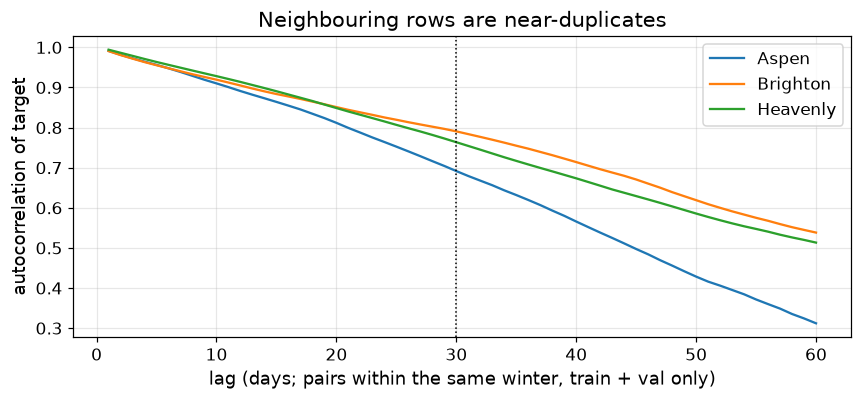

In [31]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict

DEV = T[T.split.isin(["train", "val"]) & T.y_measured].dropna(subset=BASE)
rows, acf = [], {}
for r, g in DEV.groupby("resort", sort=False):
    tv = T[(T.resort == r) & T.split.isin(["train", "val"])]          # train + val winters only; y is NaN unless measured
    acf[r] = []
    for lag in range(1, 61):                                         # pairs (t, t+lag days) within the SAME winter
        y2 = tv.y.reindex(tv.index + pd.Timedelta(days=lag)).to_numpy()
        same = tv.winter.reindex(tv.index + pd.Timedelta(days=lag)).to_numpy() == tv.winter.to_numpy()
        ok = same & ~np.isnan(y2) & tv.y.notna().to_numpy()
        acf[r].append(np.corrcoef(tv.y.to_numpy()[ok], y2[ok])[0, 1])
    X, yy, grp = g[BASE].to_numpy(), g.y.to_numpy(), g.winter.to_numpy()
    model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12)))
    p_rand = cross_val_predict(model, X, yy, cv=KFold(5, shuffle=True, random_state=0))
    p_wint = cross_val_predict(model, X, yy, cv=GroupKFold(5), groups=grp)
    rows.append({"resort": r, "rows": len(g), "winters": len(set(grp)),
                 "MAE, random 5-fold (cm)": np.abs(p_rand - yy).mean(), "MAE, grouped by winter (cm)": np.abs(p_wint - yy).mean()})
RS = pd.DataFrame(rows).set_index("resort")
RS["random split makes the error look smaller by (%)"] = 100 * (1 - RS.iloc[:, 2] / RS.iloc[:, 3])
display(RS.round(1))
fig, ax = plt.subplots(figsize=(8, 3.8))
for r, a in acf.items():
    ax.plot(range(1, 61), a, color=COL[r], label=r)
ax.axvline(30, color="k", ls=":", lw=1); ax.set_xlabel("lag (days; pairs within the same winter, train + val only)"); ax.set_ylabel("autocorrelation of target")
ax.set_title("Neighbouring rows are near-duplicates"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); plt.show()

The random split makes the same model's error look **15–24 % smaller** than the honest grouped estimate, because it is partly
being tested on near-copies of its training rows. A grouped-by-winter split is the honest estimate, and it is also how we will tune models in Milestone 3
(D-033: **cross-validation folds are whole winters**). The ridge model is only a demonstration of the leak, not our model,
and no test-winter row was used.

## 7. Baselines
All three are computed **without any test-winter data** (staff condition 4). "Training winters" means the winters available for
fitting at that stage: **train** when scoring validation, and **train + validation** (the final training set, D-032) when
scoring test.
- **Climatology** (staff condition 2, "historical averages for the same time of year"). The mean measured SNWD for the
  target's day of season, pooled within ±7 days and taken across **training winters only**. For validation scoring it is fitted
  on train; for test scoring, on train + validation. `modeltable.climatology` drops all other winters before computing
  anything, and a unit test poisons the test winters to prove it.
- **Persistence.** The depth in 30 days equals the depth today.
- **Persistence + climatological change.** Today's depth plus the change climatology expects over the next 30 days, i.e.
  `snwd_t + clim(target day) − clim(today)`, clipped at 0. It is a standard stronger reference: if our models can't beat it, they
  aren't learning anything beyond the seasonal cycle.

All baselines are scored on the **same rows**: measured target and known `snwd_t`. Errors are in cm.

In [32]:
def baselines(r, eval_split, fit_splits, halfwidth=7, fit_winters=None):
    t_, d_ = T[T.resort == r], D[r]
    fw = fit_winters if fit_winters is not None else sorted(t_[t_.split.isin(fit_splits)].winter.unique())
    cm_ = mt.climatology(d_, fw, halfwidth, "mean"); cmed = mt.climatology(d_, fw, halfwidth, "median")
    e = t_[(t_.split == eval_split) & t_.y_measured & t_.snwd_t.notna()].copy()
    e["persistence"] = e.snwd_t
    e["climatology (mean)"] = cm_.reindex(e.target_dowy).to_numpy()
    e["climatology (median)"] = cmed.reindex(e.target_dowy).to_numpy()
    e["persistence + clim. change"] = np.clip(e.snwd_t + cm_.reindex(e.target_dowy).to_numpy() - cm_.reindex(e.dowy).to_numpy(), 0, None)
    return e, cm_
BL = ["climatology (mean)", "climatology (median)", "persistence", "persistence + clim. change"]
def score(e):
    out = {}
    for b in BL:
        err = e[b] - e.y
        out[b] = {"MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean()), "bias": err.mean()}
    return pd.DataFrame(out).T
scores, E, CLIM = [], {}, {}
for r in RES:
    for ev, fit in [("val", ["train"]), ("test", ["train", "val"])]:
        e, cm_ = baselines(r, ev, fit); E[(r, ev)] = e; CLIM[(r, ev)] = cm_
        s = score(e); s["resort"], s["evaluated on"], s["n"], s["fitted on"] = r, ev, len(e), "+".join(fit)
        scores.append(s.rename_axis("baseline").reset_index())
SC = pd.concat(scores)
SC_pivot = SC.pivot_table(index=["resort", "baseline"], columns="evaluated on", values=["MAE", "RMSE", "bias"]).round(1)
SC_pivot = SC_pivot.reindex(columns=["val", "test"], level=1)
SC_pivot

MAE        RMSE        bias      
evaluated on                          val  test   val  test   val  test
resort   baseline                                                      
Aspen    climatology (mean)          16.9  14.0  20.4  21.7  -4.9   7.3
         climatology (median)        17.2  14.3  20.7  21.8  -5.3   7.4
         persistence                 24.1  22.4  28.7  26.3 -13.3 -10.5
         persistence + clim. change  12.5  11.3  16.2  14.4  -1.3   1.9
Brighton climatology (mean)          28.1  36.5  34.9  47.5  -6.1   9.1
         climatology (median)        29.9  35.0  37.7  47.2 -13.4   3.0
         persistence                 31.7  34.0  40.4  42.8 -22.6 -17.7
         persistence + clim. change  18.7  23.3  24.0  30.4  -2.2   3.2
Heavenly climatology (mean)          56.5  51.0  79.2  73.2 -23.2   5.0
         climatology (median)        57.4  48.3  82.2  73.1 -27.8  -4.9
         persistence                 44.0  41.8  61.3  56.6 -28.7 -16.8
         persistence + clim. change  36.2  31.5  49.2  42.4 -10.3   4.0

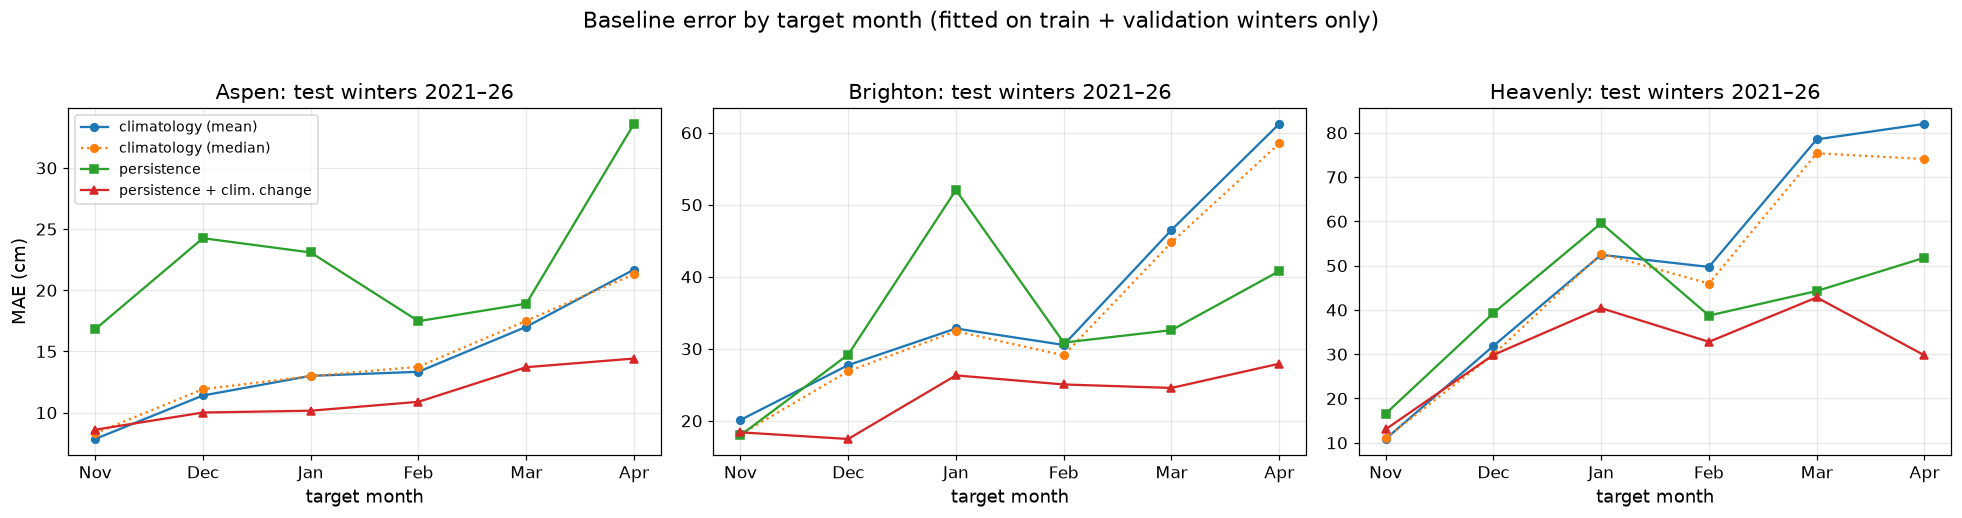

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), sharey=False)
for ax, r in zip(axes, RES):
    e = E[(r, "test")].copy(); e["month"] = e.target_date.dt.month
    order = [11, 12, 1, 2, 3, 4]
    for b, st in zip(BL, ["-o", ":o", "-s", "-^"]):
        mae = e.groupby("month").apply(lambda g: (g[b] - g.y).abs().mean()).reindex(order)
        ax.plot(range(6), mae.values, st, label=b, ms=5)
    ax.set_xticks(range(6), ["Nov", "Dec", "Jan", "Feb", "Mar", "Apr"]); ax.set_title(f"{r}: test winters 2021–26")
    ax.set_xlabel("target month"); ax.grid(alpha=.3)
axes[0].set_ylabel("MAE (cm)"); axes[0].legend(fontsize=9)
fig.suptitle("Baseline error by target month (fitted on train + validation winters only)", y=1.02)
fig.tight_layout(); savefig(fig, "baselines_by_month"); plt.show()

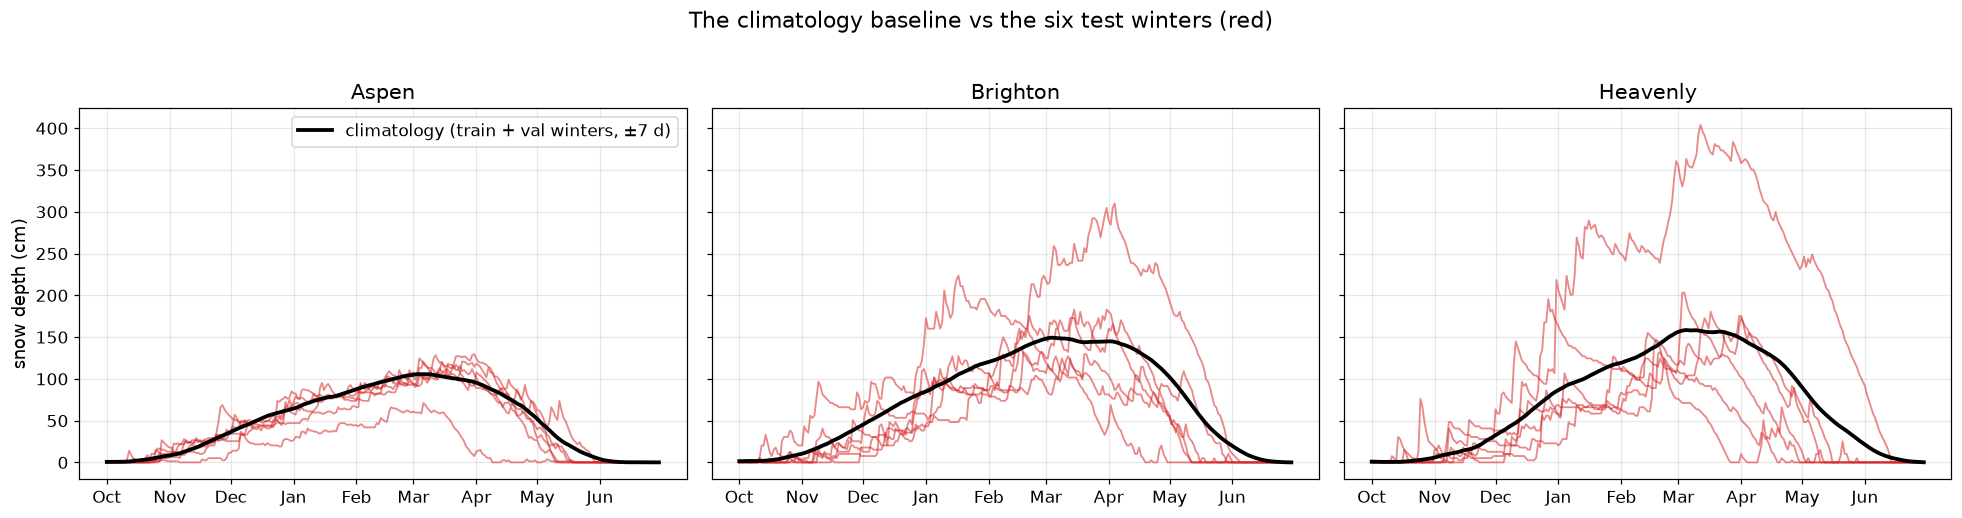

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), sharey=True)
for ax, r in zip(axes, RES):
    cm_ = CLIM[(r, "test")]
    s = S[r].copy(); s["winter"] = parse.winter_of(s.index); s["dowy"] = mt.day_of_water_year(s.index)
    for wtr, g in s[s.winter.between(2021, 2026) & (s.dowy <= 272)].groupby("winter"):
        ax.plot(g.dowy, g.snwd.where(g.snwd_measured), color=SPLIT_COL["test"], alpha=.55, lw=1.2)
    ax.plot(cm_.index, cm_.values, color="k", lw=2.5, label="climatology (train + val winters, ±7 d)")
    ax.set_xticks([0, 31, 61, 92, 123, 151, 182, 212, 243], ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun"])
    ax.set_title(f"{r}"); ax.grid(alpha=.3)
axes[0].set_ylabel("snow depth (cm)"); axes[0].legend()
fig.suptitle("The climatology baseline vs the six test winters (red)", y=1.02)
fig.tight_layout(); savefig(fig, "climatology_vs_test"); plt.show()

### 7.1 Two checks on the climatology baseline
(a) **How much would a leaky climatology flatter itself?** We fit it on **all** winters, test winters included, purely as an
illustration of why staff condition 4 matters. This variant is **never** used as a baseline.
(b) **Smoothing window.** We choose the ±k-day pooling on **validation** winters only.

In [35]:
rows = []
for r in RES:
    allw = sorted(T[T.resort == r].winter.unique())
    e_ok, _ = baselines(r, "test", ["train", "val"])
    e_bad, _ = baselines(r, "test", None, fit_winters=allw)
    rows.append({"resort": r, "MAE: proper climatology (train+val)": (e_ok["climatology (mean)"] - e_ok.y).abs().mean(),
                 "MAE: leaky climatology (incl. test winters)": (e_bad["climatology (mean)"] - e_bad.y).abs().mean()})
LK = pd.DataFrame(rows).set_index("resort")
LK["leak flatters the baseline by (%)"] = 100 * (1 - LK.iloc[:, 1] / LK.iloc[:, 0])
display(LK.round(1))
hw = {}
for h in [0, 3, 7, 15, 30]:
    hw[f"±{h} d"] = {r: (lambda e: (e["climatology (mean)"] - e.y).abs().mean())(baselines(r, "val", ["train"], halfwidth=h)[0]) for r in RES}
print("validation MAE (cm) of the mean climatology by pooling half-width:")
pd.DataFrame(hw).round(2)

,MAE: proper climatology (train+val),MAE: leaky climatology (incl. test winters),leak flatters the baseline by (%)
resort,,,
Aspen,14.0,13.3,5.0
Brighton,36.5,35.6,2.6
Heavenly,51.0,50.4,1.2


validation MAE (cm) of the mean climatology by pooling half-width:


,±0 d,±3 d,±7 d,±15 d,±30 d
Aspen,16.88,16.85,16.87,16.98,17.48
Brighton,28.11,28.07,28.12,28.32,29.27
Heavenly,56.64,56.61,56.55,56.43,56.69


**Reading these.**
- A climatology that has seen the test winters does look better on them, but only by **1–5 %**. A climatology pools 23–29
  winters, so six extra winters move the curve only modestly.
- The bigger lesson is the reverse. Even a climatology that *has* seen the answers still errs by 13–50 cm, because
  individual winters are so far from the average (§3.2). The staff condition still matters for honesty, and we enforce it in
  code and tests. But the main reason climatology is weak is the variability between winters, not the fitting window.
- The pooling half-width hardly matters: validation MAE changes by under 0.3 cm between ±0 and ±15 days. ±7 days is in that
  flat region, so the baseline doesn't depend on a tuned choice.

## 8. EDA of the modelling table (training winters only)
Feature–target relationships are explored on **training winters only**, so feature and model choices are not shaped by the
test winters. Earlier sections did look at test winters on purpose, but only for input quality control (§2.5–2.6), to
describe the target (§3.2), and to characterise the split (§6). None of those fits anything that is later scored.

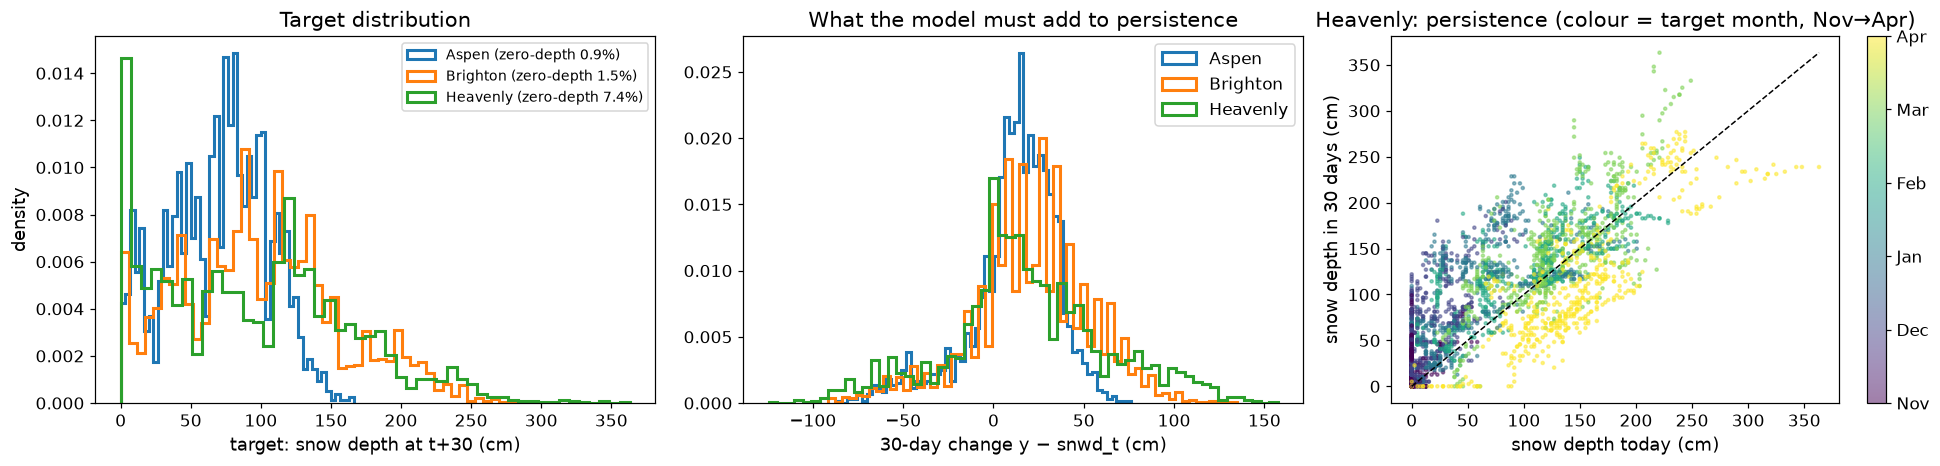

,count,mean,median,std,min,max,skew
resort,,,,,,,
Aspen,2269,70.08,74.93,34.90,0.0,166.37,-0.11
Brighton,3444,99.57,96.52,56.36,0.0,287.02,0.37
Heavenly,3082,94.38,91.44,68.23,0.0,363.22,0.48


In [36]:
TR = T[(T.split == "train") & T.y_measured]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
for r, g in TR.groupby("resort", sort=False):
    axes[0].hist(g.y, bins=50, histtype="step", lw=2, color=COL[r], label=f"{r} (zero-depth {100*(g.y==0).mean():.1f}%)", density=True)
    dlt = g.y - g.snwd_t
    axes[1].hist(dlt.dropna(), bins=60, histtype="step", lw=2, color=COL[r], density=True, label=r)
axes[0].set_xlabel("target: snow depth at t+30 (cm)"); axes[0].set_ylabel("density"); axes[0].legend(fontsize=9); axes[0].set_title("Target distribution")
axes[1].set_xlabel("30-day change y − snwd_t (cm)"); axes[1].legend(); axes[1].set_title("What the model must add to persistence")
g = TR[TR.resort == "Heavenly"]
sc = axes[2].scatter(g.snwd_t, g.y, c=g.target_date.dt.month.map({11: 0, 12: 1, 1: 2, 2: 3, 3: 4, 4: 5}), cmap="viridis", s=4, alpha=.5)
lim = [0, max(g.snwd_t.max(), g.y.max())]; axes[2].plot(lim, lim, "k--", lw=1)
axes[2].set_xlabel("snow depth today (cm)"); axes[2].set_ylabel("snow depth in 30 days (cm)"); axes[2].set_title("Heavenly: persistence (colour = target month, Nov→Apr)")
cb = fig.colorbar(sc, ax=axes[2]); cb.set_ticks(range(6)); cb.set_ticklabels(["Nov", "Dec", "Jan", "Feb", "Mar", "Apr"])
fig.tight_layout(); savefig(fig, "target_eda"); plt.show()
TR.groupby("resort").y.agg(["count", "mean", "median", "std", "min", "max", "skew"]).round(2)

### 8.1 Which features relate to the 30-day change?
The quantity a model has to learn beyond persistence is the **30-day change** `y − snwd_t`. Below are Spearman rank
correlations with that change on training winters (robust to skew and outliers).

In [37]:
TRd = TR.assign(delta=TR.y - TR.snwd_t)
corr = pd.DataFrame({r: g[BASE].corrwith(g.delta, method="spearman") for r, g in TRd.groupby("resort", sort=False)})
corr["mean |ρ|"] = corr.abs().mean(axis=1)
top = corr.sort_values("mean |ρ|", ascending=False).head(18).round(2)
top

/Users/owen/DataSci1/Final Project/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/Users/owen/DataSci1/Final Project/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:2043: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,Aspen,Brighton,Heavenly,mean |ρ|
dowy,-0.56,-0.38,-0.32,0.42
target_dowy,-0.56,-0.38,-0.32,0.42
doy_sin,-0.56,-0.38,-0.32,0.42
snowfall_wy,-0.53,-0.37,-0.33,0.41
snwd_t,-0.50,-0.38,-0.29,0.39
doy_cos,0.45,0.35,0.38,0.39
snwd_peak_wy,-0.51,-0.37,-0.29,0.39
wteq_t,-0.50,-0.37,-0.30,0.39
wteq_peak_wy,-0.50,-0.37,-0.29,0.38
precip_wy,-0.50,-0.35,-0.30,0.38


**Reading the table.**
- **Calendar and snow state dominate** (|ρ| ≈ 0.3–0.56): later in the season, and with a deeper or larger snowpack, the
  30-day change is more negative. Snow builds early and melts late, and a big snowpack has more to lose.
- Season-to-date snowfall/precipitation and ERA5-Land depth are in the same group. They are largely proxies for "how far into
  the season, and how big is the pack".
- **Weather comes next, and is weaker** (|ρ| ≈ 0.2–0.3): high pressure (7- and 30-day means), lower wind, more sunshine, and
  less recent precipitation go with *smaller* gains or larger losses. These are fair-weather spells.
- **Melt indicators (positive degree-days) are not in the top 18 when ranked across all months.** Their effect is
  concentrated in spring, which a pooled rank correlation dilutes.
- Recent snowfall matters least of all: the snow that will fall before *t* + 30 hasn't fallen yet. That is the core difficulty
  of a 30-day horizon without forecasts.

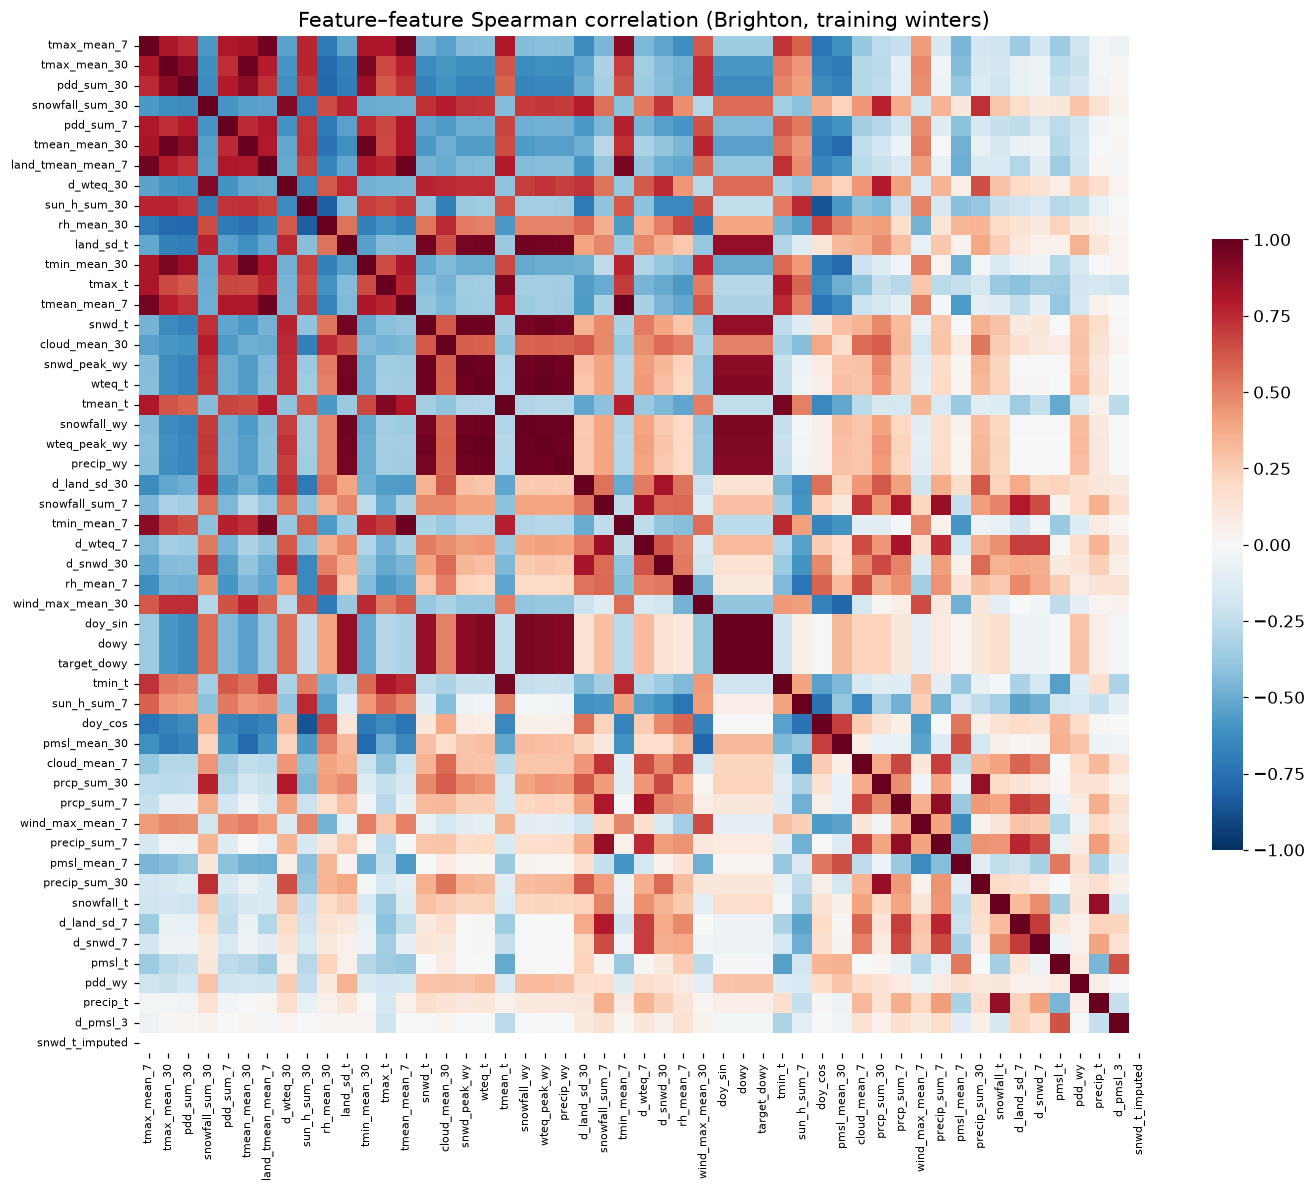

pairs with |ρ| > 0.95: 31


dowy           target_dowy          1.000
target_dowy    doy_sin              1.000
dowy           doy_sin              1.000
wteq_t         wteq_peak_wy         0.996
snowfall_wy    precip_wy            0.988
wteq_peak_wy   snowfall_wy          0.988
snwd_peak_wy   wteq_peak_wy         0.987
tmean_mean_30  tmin_mean_30         0.986
wteq_t         snowfall_wy          0.984
wteq_peak_wy   precip_wy            0.983
wteq_t         snwd_peak_wy         0.983
tmean_mean_30  tmax_mean_30         0.982
tmean_mean_7   land_tmean_mean_7    0.981
wteq_t         precip_wy            0.981
snwd_t         wteq_t               0.980
dtype: float64

In [38]:
fig, ax = plt.subplots(figsize=(13, 11))
cc = TR[TR.resort == "Brighton"][BASE].corr(method="spearman")
order = cc.abs().sum().sort_values(ascending=False).index
sns.heatmap(cc.loc[order, order], cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True, cbar_kws={"shrink": .6})
ax.tick_params(labelsize=7); ax.set_title("Feature–feature Spearman correlation (Brighton, training winters)")
fig.tight_layout(); savefig(fig, "feature_correlation"); plt.show()
pairs = cc.where(np.triu(np.ones(cc.shape, bool), 1)).stack()
print("pairs with |ρ| > 0.95:", len(pairs[pairs.abs() > .95]))
pairs[pairs.abs() > .95].sort_values(key=abs, ascending=False).head(15).round(3)

**Collinearity.** 31 pairs have |ρ| > 0.95 (Brighton, train).
- `target_dowy` is exactly `dowy + 30`, and over Oct–Mar `doy_sin` is monotone in `dowy` (ρ = 1.00). So `target_dowy` is kept
  **only for looking up climatology**, and Milestone 3 should use one calendar encoding, not three.
- Other near-duplicate groups: the three temperature statistics, ERA5 against ERA5-Land
temperature, season-to-date totals against `dowy`, and `snwd_peak_wy` against `snwd_t`. Plain linear regression would have
unstable coefficients on these. Milestone 3 should therefore use **regularised** linear regression (ridge/lasso, fitted with
winter-grouped CV) and/or prune each group to one representative. The random forest is not affected (D-035).

### 8.2 Feature scale
Features range from 0–1 indicators to running totals in the thousands. The scale matters for regularised linear models and
not for trees. **Any scaler is fitted on training rows only** and applied unchanged to validation and test, inside the
cross-validation pipeline.

In [39]:
sc_tab = TR[BASE].describe().T[["mean", "std", "min", "max"]]
sc_tab["max/std"] = (sc_tab["max"].abs() / sc_tab["std"]).round(1)
sc_tab.sort_values("std", ascending=False).round(2)

,mean,std,min,max,max/std
precip_wy,206.22,166.41,0.00,1075.80,6.5
snowfall_wy,111.27,98.30,0.00,601.79,6.1
pdd_sum_30,44.21,82.79,-0.00,406.20,4.9
pdd_wy,128.55,68.86,0.00,348.50,5.1
snwd_peak_wy,85.56,66.58,0.00,363.22,5.5
prcp_sum_30,87.15,61.57,0.00,365.76,5.9
snwd_t,72.76,60.22,0.00,363.22,6.0
precip_sum_30,69.52,52.50,0.00,373.70,7.1
target_dowy,121.43,52.33,31.00,212.00,4.1
dowy,91.43,52.33,1.00,182.00,3.5


## 9. Robustness inputs from NRCS's original readings (D-024)
NRCS edits about 29 % of depth values after the fact, sometimes months later (notebook 02 §10). A real-time forecaster would
have seen the **original** reading. The `rob_*` columns rebuild the snow-state features from originals, using only **causal**
quality control: bounds, D-020's negative-depth rule, and a **recursive trailing spike rule** (`modeltable.causal_spike_filter`).
That rule rejects a reading more than 40 in from the median of the last 7 *accepted* readings, and re-anchors after 30 days
with nothing accepted. Notebook 02's
centred spike rule can't be used here, because it needs days *t*+1 to *t*+3. The raw record has frequent multi-day sensor glitches,
such as Brighton reading 208 in on a 10 in day (2023-11-23), and a plain trailing median would adopt them after a few days. The
calibration below checks the rule against the cleaned record, which serves as the best available truth, using **training winters
(1998–2016) only**, so the threshold is not tuned on the test winters. Milestone 3 will re-score the final models with these in place of
`snwd_t` / `d_snwd_*`. Here we describe how different they are.

In [40]:
rows = []
for t in STATIONS:
    s_ = clean[(clean.station == t) & clean.winter.between(1998, 2016)].set_index("date")    # TRAINING winters only
    cl = s_.SNWD_cm / 2.54
    o = s_.SNWD_nrcs_orig.where(s_.SNWD_nrcs_orig.between(-mt.ORIG_NEG_TOL_IN, mt.ORIG_MAX_IN)).clip(lower=0)
    real_dev = (cl - cl.shift(1).rolling(7, min_periods=2).median()).abs()
    for th in [20, 30, 40, 50]:
        f_ = mt.causal_spike_filter(o, 7, th, mt.ORIG_REANCHOR_DAYS); rej = o.notna() & f_.isna()
        rows.append({"station": meta.loc[t, "name"], "threshold (in)": th,
                     "largest real deviation (cleaned, in)": round(real_dev.max(), 1),
                     "raw readings rejected": int(rej.sum()),
                     "…of which equal to the cleaned value (wrongly rejected)": int((rej & ((o - cl).abs() < 0.5)).sum()),
                     "kept but > 20 in from cleaned (missed glitches)": int((f_.notna() & ((f_ - cl).abs() > 20)).sum())})
CAL = pd.DataFrame(rows)
CAL.pivot(index="station", columns="threshold (in)", values=["raw readings rejected", "…of which equal to the cleaned value (wrongly rejected)", "kept but > 20 in from cleaned (missed glitches)"])

raw readings rejected                …of which equal to the cleaned value (wrongly rejected)              kept but > 20 in from cleaned (missed glitches)            
threshold (in)                     20   30   40   50                                                      20   30  40  50                                              20  30  40  50
station                                                                                                                                                                              
Brighton                          404  296  293  293                                                 96         3   0   0                                               0   0   0   0
Brumley                            96   96   95   95                                                 30        30  30  30                                               0   0   1   1
Heavenly Valley                   486  207   96   93                                                364       104   3   3                                               3  28  31  32
Kiln                              138  137  137  137                                                  1         0   0   0                                               0   0   0   0

**Calibration** (training winters 1998–2016 only)
- At 40 in, the rule removes Kiln's 137 and Brighton's 293 glitch readings with **no** wrong rejections and no missed glitches.
- Heavenly has 3 wrong rejections and 31 missed glitches. A lower threshold would wrongly reject real big-storm days there:
  104 at 30 in, 364 at 20 in.
- Brumley has 30 wrong rejections at **every** threshold, so these are not a threshold effect. They are cases where the
  reference itself was a glitch: the start of the record, or a re-anchor after a long gap (a documented limitation of
  `causal_spike_filter`).
- That is the realistic price of quality control without hindsight, and it is what the robustness run should measure.

In [41]:
rows = []
for r, g in T.groupby("resort", sort=False):
    both_ = g.dropna(subset=["snwd_t", "rob_snwd_t"])
    dlt = both_.rob_snwd_t - both_.snwd_t
    rows.append({"resort": r, "rows with both": len(both_), "identical (%)": 100 * (dlt.abs() < 0.01).mean(),
                 "|Δ| > 5 cm (%)": 100 * (dlt.abs() > 5).mean(), "median |Δ| where differ (cm)": dlt[dlt.abs() >= .01].abs().median(),
                 "rob_snwd_t NaN where snwd_t present": int((g.snwd_t.notna() & g.rob_snwd_t.isna()).sum())})
display(pd.DataFrame(rows).set_index("resort").round(2))
g = T.assign(d=(T.rob_snwd_t - T.snwd_t).abs() > 0.01).groupby(["resort", "split"]).d.mean().unstack()[["train", "val", "test"]] * 100
print("share of rows where the original differs from the edited value (%), by split:"); g.round(1)

,rows with both,identical (%),|Δ| > 5 cm (%),median |Δ| where differ (cm),rob_snwd_t NaN where snwd_t present
resort,,,,,
Aspen,3662,86.81,2.02,1.27,458
Brighton,4780,90.84,3.08,2.54,471
Heavenly,4846,91.58,0.74,2.54,48


share of rows where the original differs from the edited value (%), by split:


split,train,val,test
resort,,,
Aspen,11.0,8.6,14.9
Brighton,8.0,9.9,8.4
Heavenly,10.9,4.3,3.8


**Reading these.**
- See the table above for how often originals and edited values agree exactly, and how large the typical difference is. Most
  differences are one-inch steps or noise around zero depth.
- The second table shows whether the share of rows that differ **changes between splits**.

If the share of edited values differs between splits (recent winters are mostly still provisional, notebook 02 §10), then the
inputs available at evaluation time differ systematically from training. That is exactly what the D-024 robustness run is for.

## 10. Outputs
- `data/processed/model_table.parquet`: one row per (resort, issue date); every feature, the target, flags and the split.
- `data/processed/model_table_columns.csv`: data dictionary, generated from the feature catalogue.
- `data/processed/baseline_scores.csv`: §7 scores (validation fitted on train; test fitted on train + validation).
- `figures/03_*.png`: plots for the slides.

In [42]:
SAVE = T.reset_index().rename(columns={"date": "issue_date"})
SAVE.to_parquet(OUT / "model_table.parquet", index=False)
extra = pd.DataFrame([
    ("issue_date", "label", "—", "issue date t (forecast made at end of day t)", "date"),
    ("resort", "label", "—", "resort (src/sites.py RESORTS)", ""),
    ("target_date", "label", "—", "t + 30 days (always Nov 1 – Apr 30)", "date"),
    ("y", "target", "SNOTEL", "snow depth at target_date (Aspen: Kiln+Brumley composite)", "cm"),
    ("y_measured", "target", "SNOTEL", "True if y is measured (not imputed, all members present) — ONLY these rows are labels/truth", "bool"),
    ("winter", "label", "—", "season-end year of target_date (== that of issue_date)", ""),
    ("split", "label", "—", "train (≤2016) / val (2017–2020) / test (2021–2026) — D-032", ""),
], columns=["feature", "group", "source", "definition", "unit"])
DICT = pd.concat([extra, FEAT_CAT]).rename(columns={"feature": "column"})
assert set(DICT.column) == set(SAVE.columns), set(SAVE.columns) ^ set(DICT.column)
DICT.to_csv(OUT / "model_table_columns.csv", index=False)
SC.to_csv(OUT / "baseline_scores.csv", index=False)
for p in ["model_table.parquet", "model_table_columns.csv", "baseline_scores.csv"]:
    print(f"{p:28s} {(OUT/p).stat().st_size/1e6:6.2f} MB  sha256 {sha(OUT/p)[:16]}…")
print("table:", SAVE.shape, "| figures:", sorted(f.name for f in FIG.glob("03_*.png")))

model_table.parquet            2.01 MB  sha256 dde6583f005fba55…
model_table_columns.csv        0.00 MB  sha256 7c6b7fce0cd39879…
baseline_scores.csv            0.00 MB  sha256 fe4ca7dee470bc4b…
table: (14319, 61) | figures: ['03_aspen_composite.png', '03_baselines_by_month.png', '03_climatology_vs_test.png', '03_feature_correlation.png', '03_homogeneity.png', '03_seasonal_curves.png', '03_split_winters.png', '03_target_eda.png', '03_weather_distributions.png']


## 11. Findings and proposed decisions
Numbers marked † are printed in this notebook's outputs. Decisions are recorded as **PROPOSED** in `docs/DECISIONS.md` until
a group member accepts them.

| # | Decision (PROPOSED) | Evidence |
|---|---|---|
| D-029 | **Rows = issue dates whose target date (t + 30) is in Nov 1 – Apr 30**, so issue dates run Oct 2 – Mar 31. A row is a label only if the target is measured (not imputed, all composite members present). | Matches the revised question's season. The issue and target date are always in the same winter (asserted). §5 funnel† |
| D-030 | **No cleaning of the Open-Meteo values**: no NaN, no imputation, no outlier removal. Snowfall and precipitation are separately derived and not mutually consistent, so never derive rain as precip − snowfall/0.7 (this revises D-027's remark on `rain_sum`). | §2.2 complete calendars and seams; §2.3 / 2.3a; §2.4 extremes are documented storms |
| D-031 | **Feature set**: 7- and 30-day trailing windows plus day-t values and season-to-date totals; temperatures from Open-Meteo only; SNOTEL supplies snow state and precipitation; Aspen weather = mean of the member stations' requests; strict windows (a missing day gives NaN). | §2.5 (sensor bias), §2.6 agreement table†, §2.7, §4 catalogue |
| D-032 | **Split by winter, common to all resorts**: train ≤ 2016, validation 2017–2020, test 2021–2026 (touched once; final fit on train + validation). | §6 counts†, the test winters span record and lean years†; distribution shift stated |
| D-033 | **Cross-validation folds are whole winters** (grouped or expanding-window); never shuffled days. | §6.1: a random split flatters the same model† |
| D-034 | **Hindcast caveat**: day-t reanalysis stands in for a real-time analysis (ERA5 lags ~5 days). MS3 sensitivity run: weather features lagged 5 days. | §4.3 |
| D-035 | **Baselines**: climatology = mean of measured SNWD at the target's day of season, ±7 days, training winters only (fitted on train for validation, on train + validation for test); persistence; plus *persistence + climatological change* as the strongest simple reference. Models must also handle collinearity (ridge/lasso or pruning). | §7 scores†, §7.1 half-width check and leak demonstration†, §8.1 collinearity |
| D-036 | Open-Meteo grid cells: accept the default `cell_selection=land` (an elevation-matched land cell) and record the returned cells. Future requests set `cell_selection=land` explicitly. | §2.1 table |
| D-037 | Causal QC for NRCS original readings (robustness inputs): bounds, D-020 negatives, recursive trailing spike rule (40 in vs the median of readings accepted in the previous 7 days). | §9 calibration table |

**What this means for the question.** Neither of the staff-required baselines dominates. Climatology beats persistence where
winters are regular (Aspen), persistence beats climatology where they swing widely (Heavenly), and combining the two is
better than either†. Test MAE: Aspen 11.3 vs 14.0 / 22.4 cm; Brighton 23.3 vs 36.5 / 34.0; Heavenly 31.5 vs 51.0 / 41.8.
Errors grow towards spring, when climatology is worst in March–April at Brighton and Heavenly (§7 figure). The Milestone 3 question is whether weather and snow-state features beat **persistence + climatological
change** on the 2021–2026 winters. That is a demanding but fair bar.